In [1]:
CUDA_VISIBLE_DEVICES=4
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import os
plt.style.use("default")
import re

In [2]:
# Define the absolute paths to the results files
EXPERIMENT_DIR_INDIV = "../../../experiments/cost_fixed/"
EXPERIMENT_DIR_JOINT = "../../../experiments/cost_semivariable/"

METRICS = ['cityblock', 'euclidean', 'sqeuclidean', 'minkowski', 'chebyshev', 'canberra']

METRIC_LABELS = {
    'cityblock':   r'$L_1$',
    'euclidean':   r'$L_2$',
    'sqeuclidean': r'$L_2^2$',
    'minkowski':   r'$L_3$',
    'chebyshev':   r'$L_\infty$',
    'canberra':    r'Canberra',
}

# Model directory templates
MODEL_INDIV_TEMPLATE = "model_dim768_context512_tflayers24_tfheads16_num_prefix1_dropout0_flashTrue_data100K_rowwise_costfixed_prec4_bins30_DigitTokenizer_epochs50_batch192_{}"
MODEL_JOINT_NAME     = "model_dim768_context512_tflayers24_tfheads16_num_prefix1_dropout0_flashTrue_data600K_rowwise_costsemivariable_prec4_bins30_DigitTokenizer_epochs25_batch128"

In [3]:
def load_results(path_tot, path_not):
    if not os.path.exists(path_tot):
        print(f"Error: File not found: {path_tot}")
        return None, None
    if not os.path.exists(path_not):
        print(f"Error: File not found: {path_not}")
        return None, None
        
    print(f"Loading {path_tot}...")
    data_tot = np.load(path_tot, allow_pickle=True)
    print(f"Loading {path_not}...")
    data_not = np.load(path_not, allow_pickle=True)
    
    return data_tot, data_not

def extract_metrics(data_array):
    if data_array is None: return {}
    
    metrics = {
        'MAE': [],
        'MAPE': [],
        'Hellinger': [],
        'OT Cost Diff': [],
        'Total Variation': [],
        'Run Time (Seconds)': []
    }
    
    for item in data_array:
        # Dictionary keys from run_inference.py
        if 'mae_sparse' in item: metrics['MAE'].append(item['mae_sparse'])
        if 'mape_sparse' in item: metrics['MAPE'].append(item['mape_sparse'])
        if 'hellinger_sparse' in item: metrics['Hellinger'].append(item['hellinger_sparse'])
        if 'otcost_diff' in item: metrics['OT Cost Diff'].append(item['otcost_diff'])
        if 'tv_sparse' in item: metrics['Total Variation'].append(item['tv_sparse'])
        if 'run_time' in item: metrics['Run Time (Seconds)'].append(item['run_time'])
            
    return metrics


Loading data for metric: cityblock...
Loading ../../../experiments/cost_fixed/model_dim768_context512_tflayers24_tfheads16_num_prefix1_dropout0_flashTrue_data100K_rowwise_costfixed_prec4_bins30_DigitTokenizer_epochs50_batch192_cityblock/eval_all_pairs_1d_cityblock_results_tot.npy...
Loading ../../../experiments/cost_fixed/model_dim768_context512_tflayers24_tfheads16_num_prefix1_dropout0_flashTrue_data100K_rowwise_costfixed_prec4_bins30_DigitTokenizer_epochs50_batch192_cityblock/eval_all_pairs_1d_cityblock_results_not.npy...
Loading ../../../experiments/cost_semivariable/model_dim768_context512_tflayers24_tfheads16_num_prefix1_dropout0_flashTrue_data600K_rowwise_costsemivariable_prec4_bins30_DigitTokenizer_epochs25_batch128/eval_all_pairs_1d_cityblock_results_tot.npy...
Loading ../../../experiments/cost_semivariable/model_dim768_context512_tflayers24_tfheads16_num_prefix1_dropout0_flashTrue_data600K_rowwise_costsemivariable_prec4_bins30_DigitTokenizer_epochs25_batch128/eval_all_pairs_1d

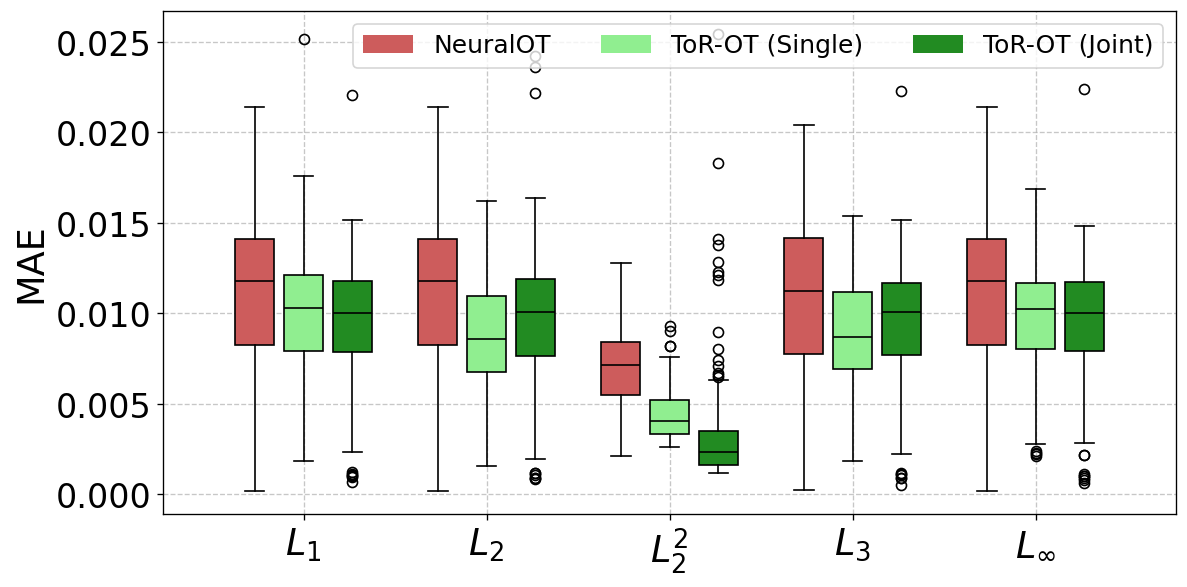

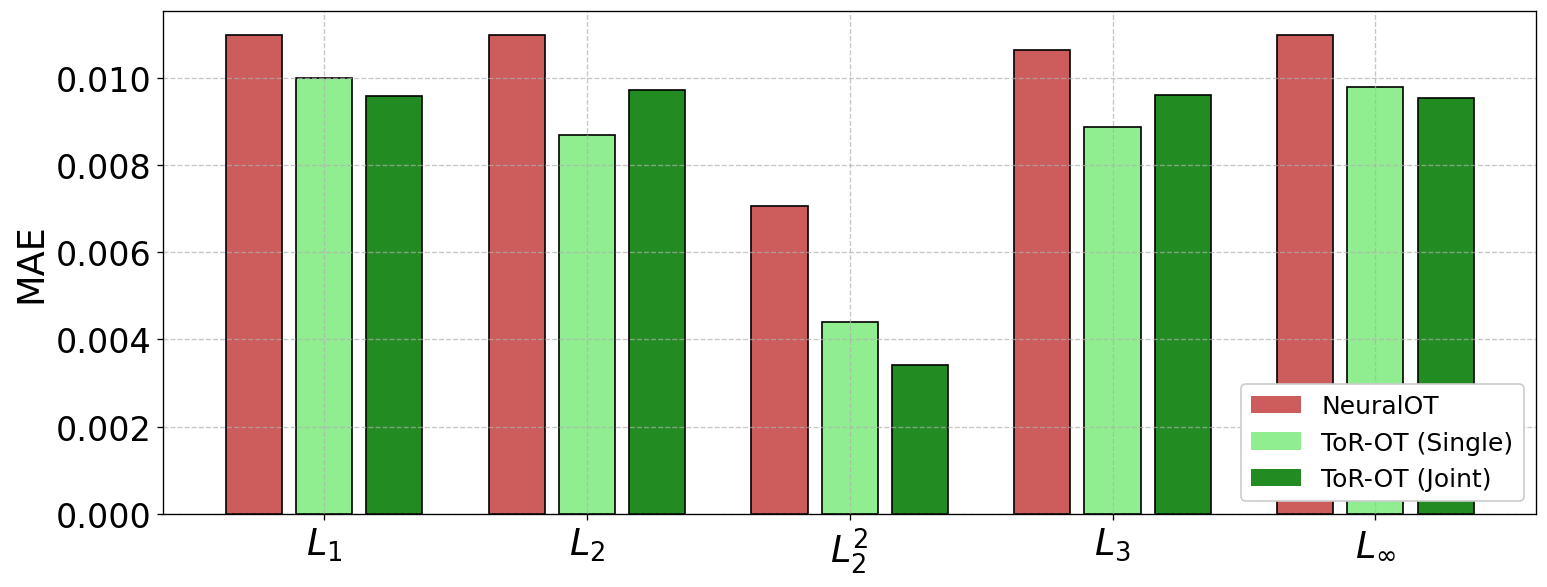

Generating plot for MAPE...
Saved: img/1d_ood_mape.png


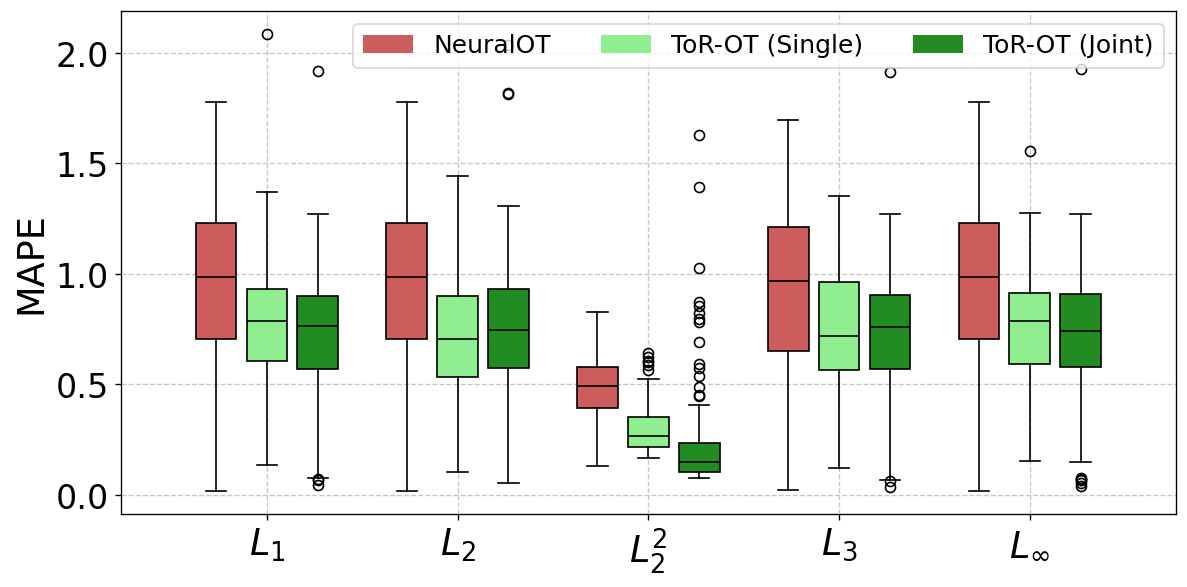

Saved: img/1d_ood_mape_bar.png


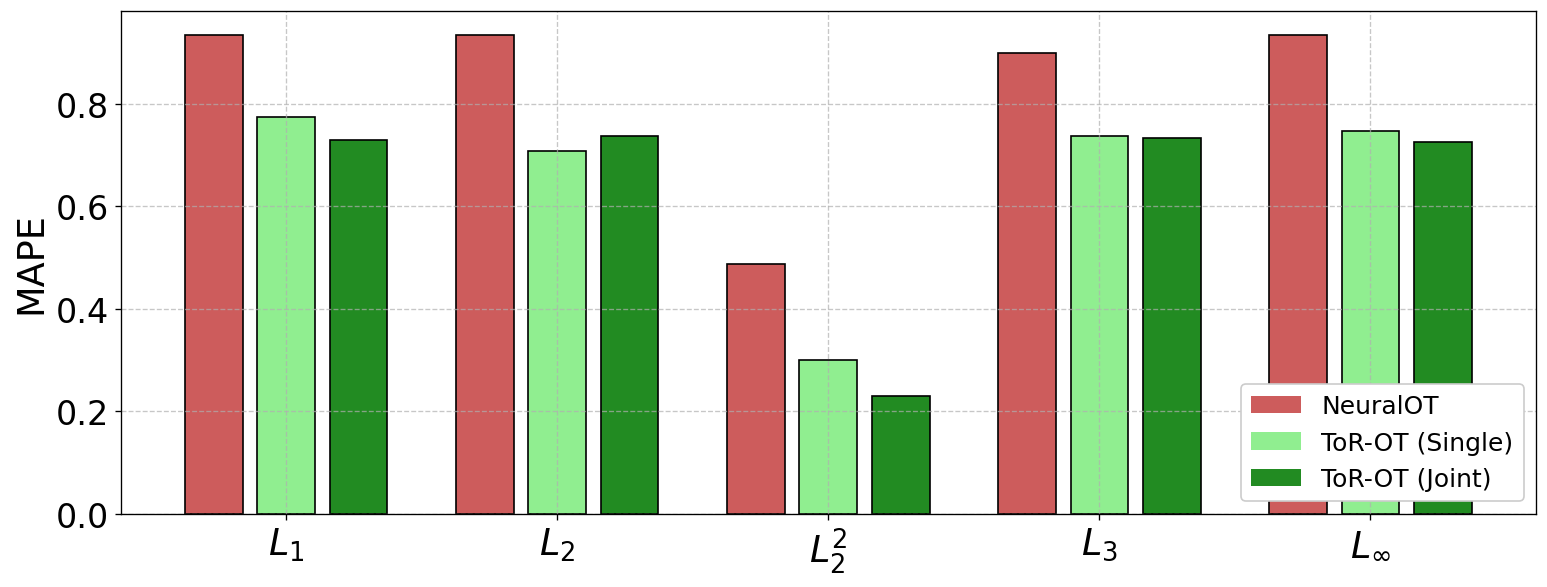

Generating plot for Hellinger...


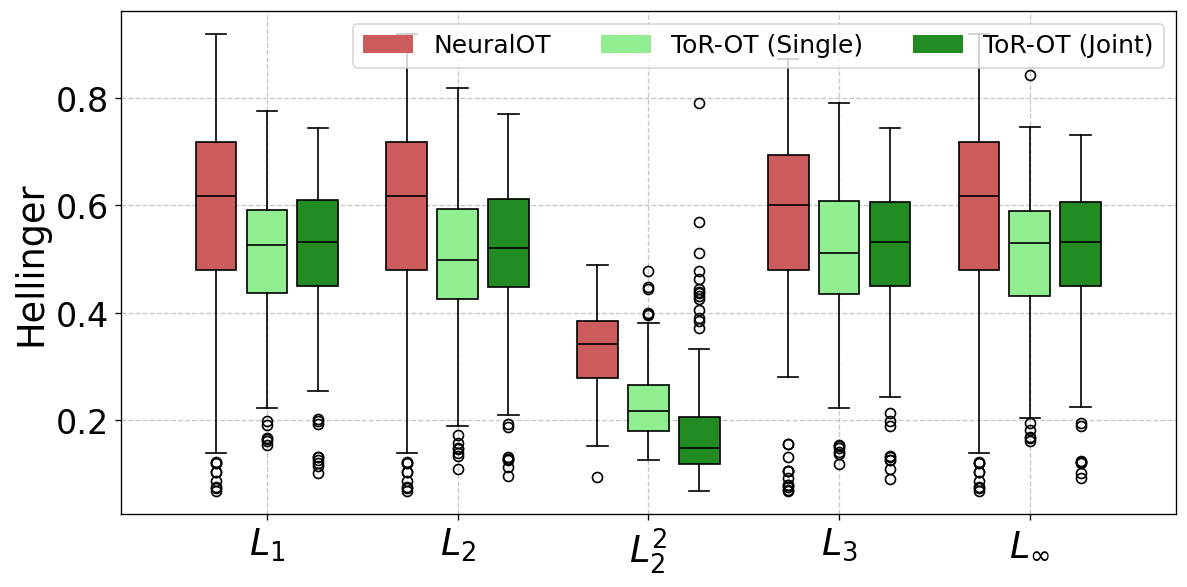

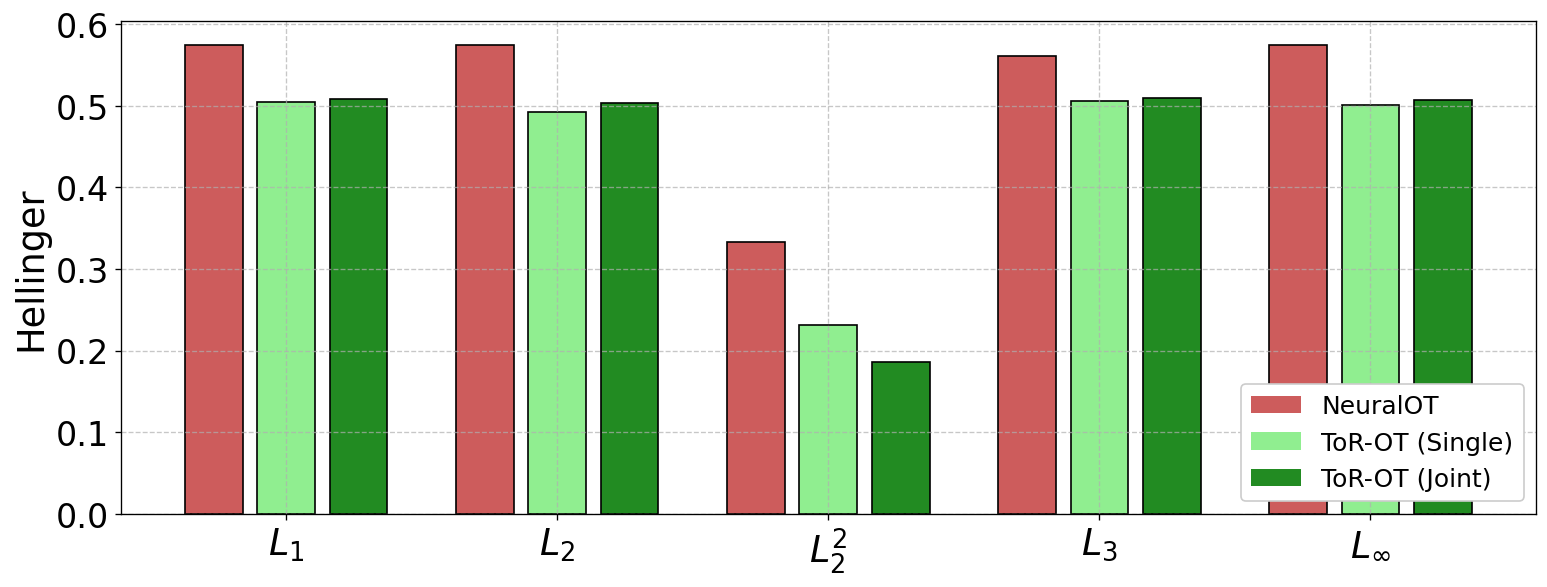

Generating plot for OT Cost Diff...


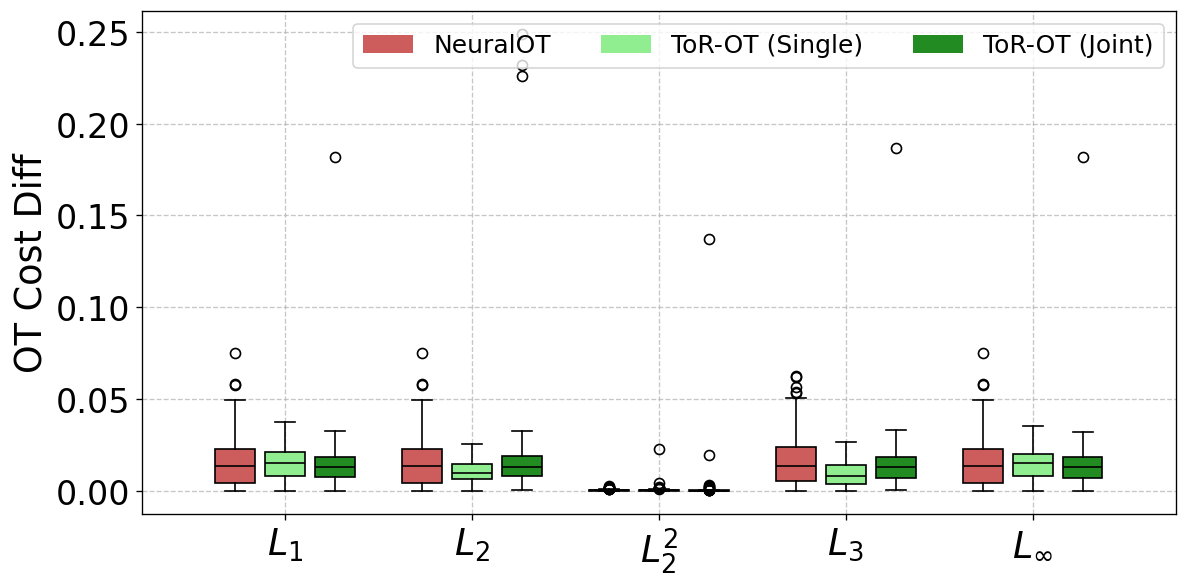

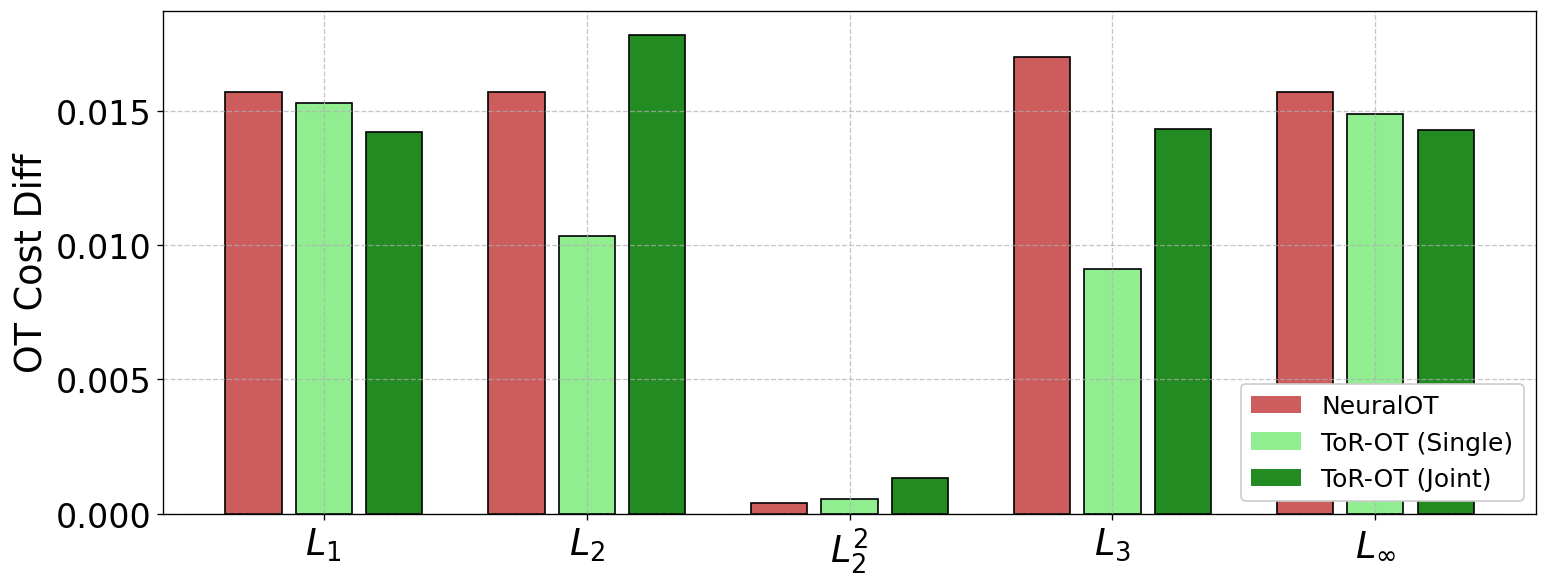

Generating plot for Total Variation...


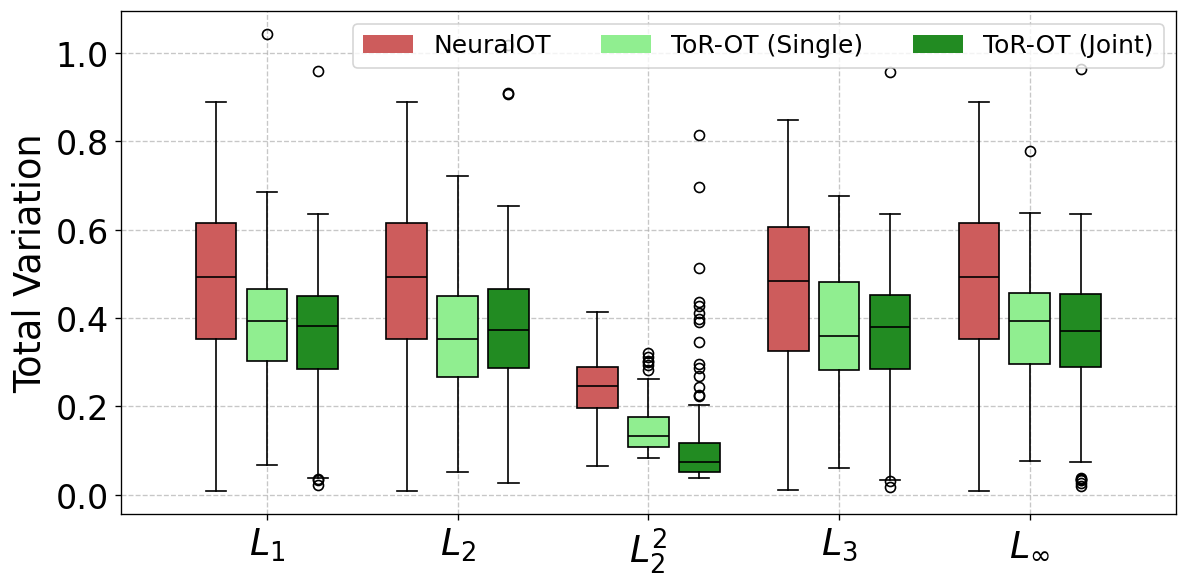

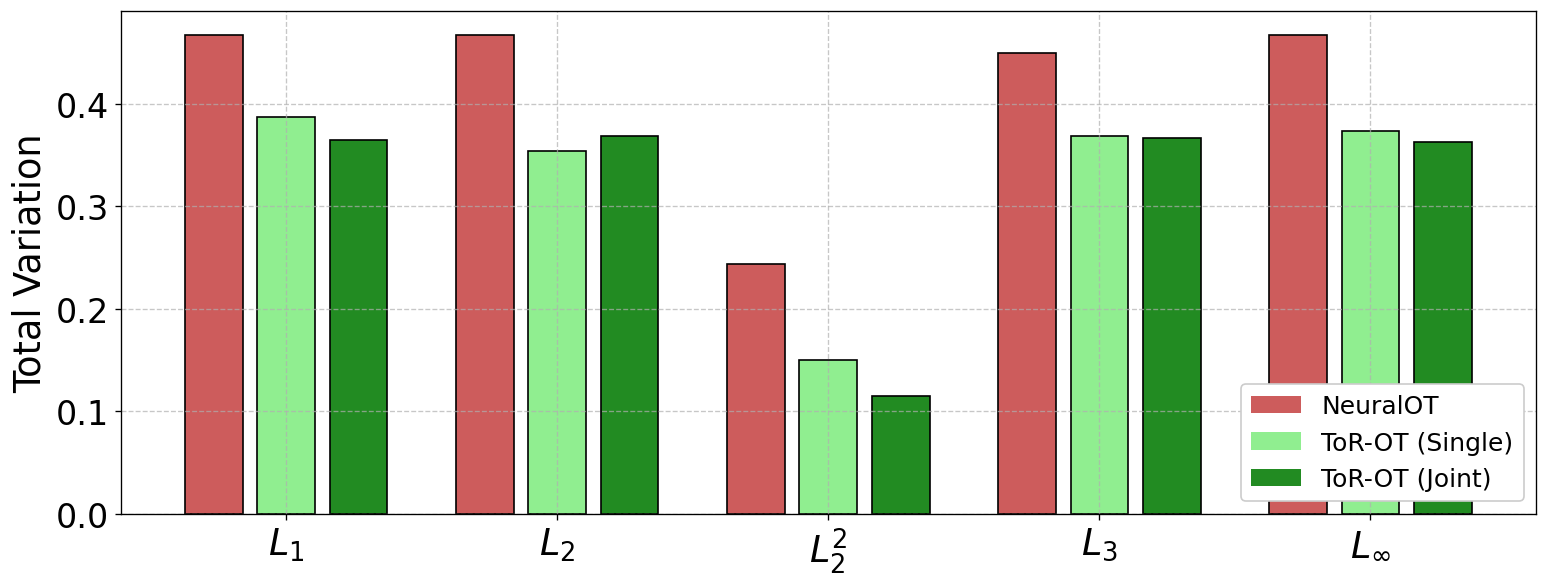

Generating plot for Run Time (Seconds)...
Saved: img/1d_ood_run_time_seconds.png


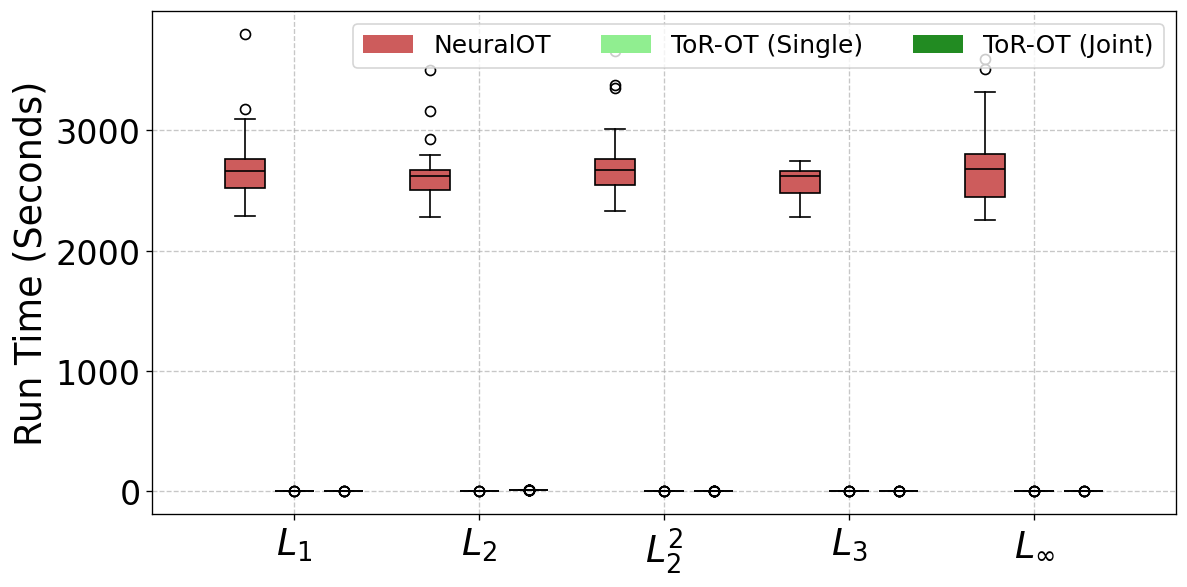

Saved: img/1d_ood_run_time_seconds_bar.png


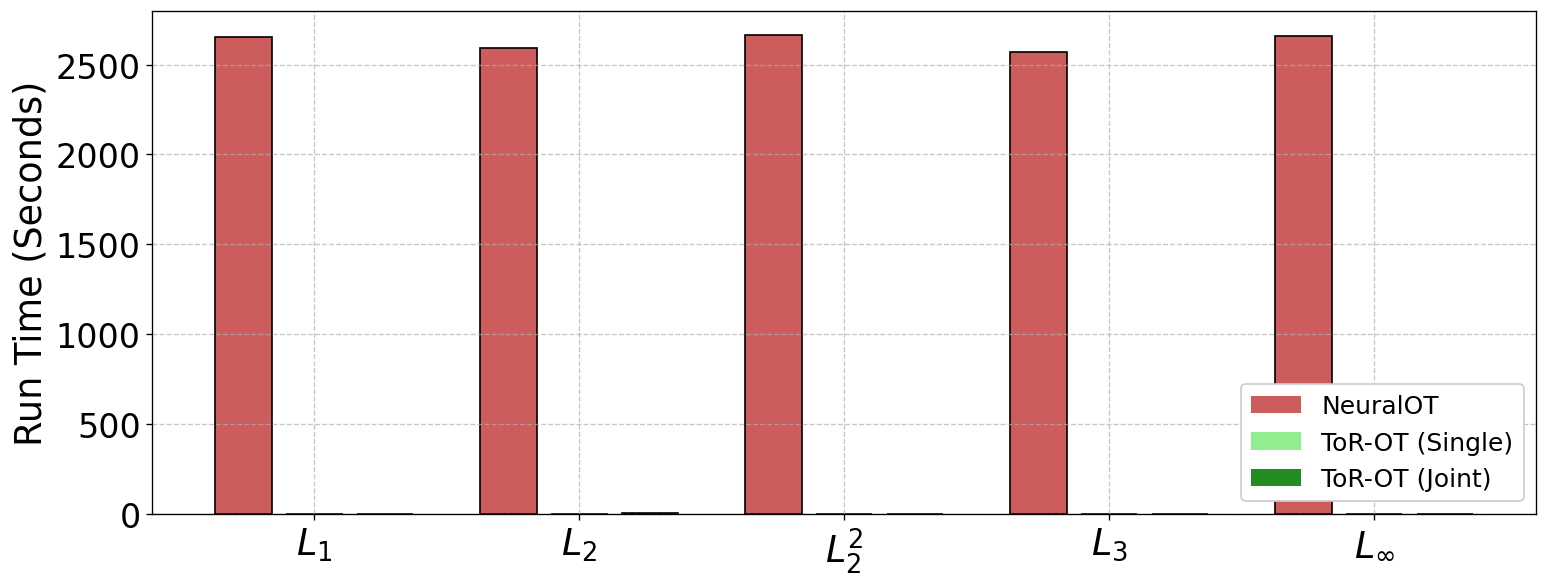

[np.float64(2627.0772160569827), np.float64(1.0925941586494445), np.float64(2.066837220059501)]
Saved: img/1d_ood_run_time_seconds_bar_single.png


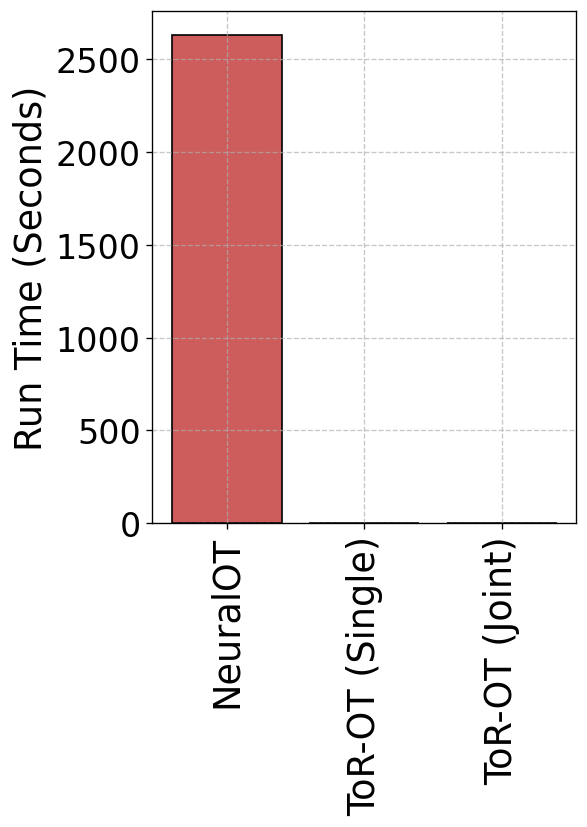

In [4]:
PERFORMANCE_METRICS = ['MAE', 'MAPE', 'Hellinger', 'OT Cost Diff', 'Total Variation', 'Run Time (Seconds)']

# Initialize data structure to hold results for all metrics
# Structure: { metric_name: { 'TOT_INDIV': ..., 'NOT_INDIV': ..., 'TOT_JOINT': ... } }
all_results_data = {}

# --- Step 1: Load ALL Data ---
for metric in METRICS:
    print(f"Loading data for metric: {metric}...")
    
    # Dynamic paths for INDIV experiments
    model_dir_indiv = MODEL_INDIV_TEMPLATE.format(metric)
    path_indiv_tot = os.path.join(EXPERIMENT_DIR_INDIV, model_dir_indiv, f"eval_all_pairs_1d_{metric}_results_tot.npy")
    path_indiv_not = os.path.join(EXPERIMENT_DIR_INDIV, model_dir_indiv, f"eval_all_pairs_1d_{metric}_results_not.npy")
    
    # Dynamic paths for JOINT experiments
    # Note: MODEL_JOINT_NAME is constant, but filename depends on metric
    path_joint_tot = os.path.join(EXPERIMENT_DIR_JOINT, MODEL_JOINT_NAME, f"eval_all_pairs_1d_{metric}_results_tot.npy")
    path_joint_not = os.path.join(EXPERIMENT_DIR_JOINT, MODEL_JOINT_NAME, f"eval_all_pairs_1d_{metric}_results_not.npy")
    
    data_indiv_tot, data_indiv_not = load_results(path_indiv_tot, path_indiv_not)
    data_joint_tot, _ = load_results(path_joint_tot, path_joint_not) # We ignore data_joint_not
    
    if data_indiv_tot is None or data_joint_tot is None:
        print(f"Skipping {metric} due to missing data.")
        continue
        
    all_results_data[metric] = {
        'NOT_INDIV': extract_metrics(data_indiv_not),
        'TOT_INDIV': extract_metrics(data_indiv_tot),
        'TOT_JOINT': extract_metrics(data_joint_tot),
        # 'NOT_JOINT' excluded
    }

# --- Step 2: Generate Plots by Performance Metric ---

# Data Keys used to access the dictionary
DATA_KEYS = ['NOT_INDIV', 'TOT_INDIV', 'TOT_JOINT']

# Mapping from Data Keys to Display Labels
LABEL_MAPPING = {
    'NOT_INDIV': 'NeuralOT',
    'TOT_INDIV': 'ToR-OT (Single)',
    'TOT_JOINT': 'ToR-OT (Joint)'
}

COLORS = ['indianred', 'lightgreen', 'forestgreen']
mpl.rcParams['ytick.labelsize'] = 20


for perf_metric in PERFORMANCE_METRICS:
    print(f"Generating plot for {perf_metric}...")
    
    # Prepare data for plotting
    plot_data = []
    valid_metrics = [] # To keep track of which distance metrics we actually have data for
    
    for dist_metric in METRICS:
        if dist_metric in all_results_data:
            valid_metrics.append(dist_metric)
            metric_data = all_results_data[dist_metric]
            
            # Append data in the order of DATA_KEYS
            for key in DATA_KEYS:
                # The extract_metrics returns a dict like {'MAE': [...], ...}
                values = metric_data[key].get(perf_metric, [])
                plot_data.append(values)
    
    if not plot_data:
        print(f"No data found to plot for {perf_metric}")
        continue

    fig, ax = plt.subplots(figsize=(10, 5), dpi=120)
    
    # Position calculations
    num_distance_metrics = len(valid_metrics)
    num_bars_per_group = len(DATA_KEYS)
    group_width = 0.8
    bar_width = group_width / num_bars_per_group
    
    # Calculate positions for all boxplots
    positions = []
    for i in range(num_distance_metrics):
        center = i + 1
        # Offsets calculation centered around the group
        start_offset = -(num_bars_per_group - 1) * bar_width / 2.0
        for j in range(num_bars_per_group):
            offset = start_offset + (j * bar_width)
            positions.append(center + offset)
            
    # Create boxplots
    bp = ax.boxplot(plot_data, positions=positions, widths=bar_width*0.8, patch_artist=True, medianprops=dict(color="black"))
    
    


    # Color the boxplots
    for i, patch in enumerate(bp['boxes']):
        # Cycle through the colors
        color_idx = i % num_bars_per_group
        patch.set_facecolor(COLORS[color_idx])
        
    # Set X-axis labels
    ax.set_xticks(range(1, num_distance_metrics + 1))
    # Use mapped labels for X-axis
    xtick_labels = [METRIC_LABELS.get(m, m) for m in valid_metrics]
    ax.set_xticklabels(xtick_labels, rotation=0, ha='center', fontsize=22)
    
    #ax.set_title(f'OOD comparison: {perf_metric} across cost types', fontsize=24)
    #ax.set_title(f'Run Time across cost types', fontsize=24)
    ax.set_ylabel(perf_metric, fontsize=22)
    ax.grid(True, linestyle='--', alpha=0.7)
    
    # Custom Legend using Mapped Labels
    from matplotlib.patches import Patch
    # Use DATA_KEYS order to get colors and map to labels
    legend_elements = [
        Patch(facecolor=COLORS[i], label=LABEL_MAPPING[DATA_KEYS[i]]) 
        for i in range(len(DATA_KEYS))
    ]
    ax.legend(handles=legend_elements, loc='upper right', fontsize=15, ncols=3)
    
    plt.tight_layout()
    # Save only selected metrics
    if perf_metric in ['MAPE', 'Run Time (Seconds)']:
        # make a filesystem-safe name like: testset_mape.png, testset_run_time_seconds.png
        safe_metric = re.sub(r'[^a-z0-9]+', '_', perf_metric.lower()).strip('_')
        out_png = f"img/1d_ood_{safe_metric}.png"
        plt.savefig(out_png, bbox_inches='tight', dpi=300)
        print(f"Saved: {out_png}")
    plt.show()


    fig, ax = plt.subplots(figsize=(13, 5), dpi=120)

    plot_data_np = np.mean(np.array(plot_data), 1)
    bp = ax.bar(positions, plot_data_np, width=bar_width*0.8, facecolor=5*COLORS, edgecolor='black')

    # Set X-axis labels
    ax.set_xticks(range(1, num_distance_metrics + 1))
    # Use mapped labels for X-axis
    xtick_labels = [METRIC_LABELS.get(m, m) for m in valid_metrics]
    ax.set_xticklabels(xtick_labels, rotation=0, ha='center', fontsize=22)
    
    #ax.set_title(f'OOD comparison: {perf_metric} across cost types', fontsize=24)
    #ax.set_title(f'Run Time across cost types', fontsize=24)
    ax.set_ylabel(perf_metric, fontsize=22)
    ax.grid(True, linestyle='--', alpha=0.7)
    
    # Custom Legend using Mapped Labels
    from matplotlib.patches import Patch
    # Use DATA_KEYS order to get colors and map to labels
    legend_elements = [
        Patch(facecolor=COLORS[i], label=LABEL_MAPPING[DATA_KEYS[i]]) 
        for i in range(len(DATA_KEYS))
    ]
    ax.legend(handles=legend_elements, loc='lower right', fontsize=15, ncols=1, framealpha=1)
    
    plt.tight_layout()
    # Save only selected metrics
    if perf_metric in ['MAPE', 'Run Time (Seconds)']:
        # make a filesystem-safe name like: testset_mape.png, testset_run_time_seconds.png
        safe_metric = re.sub(r'[^a-z0-9]+', '_', perf_metric.lower()).strip('_')
        out_png = f"img/1d_ood_{safe_metric}_bar.png"
        plt.savefig(out_png, bbox_inches='tight', dpi=300)
        print(f"Saved: {out_png}")
    plt.show()



    if (perf_metric == 'Run Time (Seconds)'):

        fig, ax = plt.subplots(figsize=(5, 7), dpi=120)
        bp = ax.bar([0, 1, 2], [np.mean(plot_data_np[::3]), np.mean(plot_data_np[1::3]), np.mean(plot_data_np[2::3])], width=0.8, facecolor=COLORS, edgecolor='black')

        print ([np.mean(plot_data_np[::3]), np.mean(plot_data_np[1::3]), np.mean(plot_data_np[2::3])])

        # Set X-axis labels
        ax.set_xticks(range(3))
        # Use mapped labels for X-axis
        xtick_labels = ['NeuralOT','ToR-OT (Single)','ToR-OT (Joint)']
        ax.set_xticklabels(xtick_labels, rotation=90, ha='center', fontsize=22)
        
        #ax.set_title(f'OOD comparison: {perf_metric} across cost types', fontsize=24)
        #ax.set_title(f'Run Time across cost types', fontsize=24)
        ax.set_ylabel(perf_metric, fontsize=22)
        ax.grid(True, linestyle='--', alpha=0.7)
        
        # Custom Legend using Mapped Labels
        # from matplotlib.patches import Patch
        # # Use DATA_KEYS order to get colors and map to labels
        # legend_elements = [
        #     Patch(facecolor=COLORS[i], label=LABEL_MAPPING[DATA_KEYS[i]]) 
        #     for i in range(len(DATA_KEYS))
        # ]
        # ax.legend(handles=legend_elements, loc='lower right', fontsize=15, ncols=1, framealpha=1)
        
        plt.tight_layout()
        # Save only selected metrics
        safe_metric = re.sub(r'[^a-z0-9]+', '_', perf_metric.lower()).strip('_')
        out_png = f"img/1d_ood_{safe_metric}_bar_single.png"
        plt.savefig(out_png, bbox_inches='tight', dpi=300)
        print(f"Saved: {out_png}")
        plt.show()



TEST SET ANALYSIS
../../../experiments/cost_fixed/model_dim768_context512_tflayers24_tfheads16_num_prefix1_dropout0_flashTrue_data100K_rowwise_costfixed_prec4_bins30_DigitTokenizer_epochs50_batch192_cityblock
['all_mae_sparse', 'all_mape_sparse', 'all_hellinger_sparse', 'all_otcost_diff', 'all_tv_sparse', 'results_by_metric']
['all_mae_sparse', 'all_mape_sparse', 'all_hellinger_sparse', 'all_otcost_diff', 'all_tv_sparse', 'results_by_metric']
['all_mae_sparse', 'all_mape_sparse', 'all_hellinger_sparse', 'all_otcost_diff', 'all_tv_sparse', 'results_by_metric']
../../../experiments/cost_fixed/model_dim768_context512_tflayers24_tfheads16_num_prefix1_dropout0_flashTrue_data100K_rowwise_costfixed_prec4_bins30_DigitTokenizer_epochs50_batch192_euclidean
['all_mae_sparse', 'all_mape_sparse', 'all_hellinger_sparse', 'all_otcost_diff', 'all_tv_sparse', 'results_by_metric']
['all_mae_sparse', 'all_mape_sparse', 'all_hellinger_sparse', 'all_otcost_diff', 'all_tv_sparse', 'results_by_metric']
['all

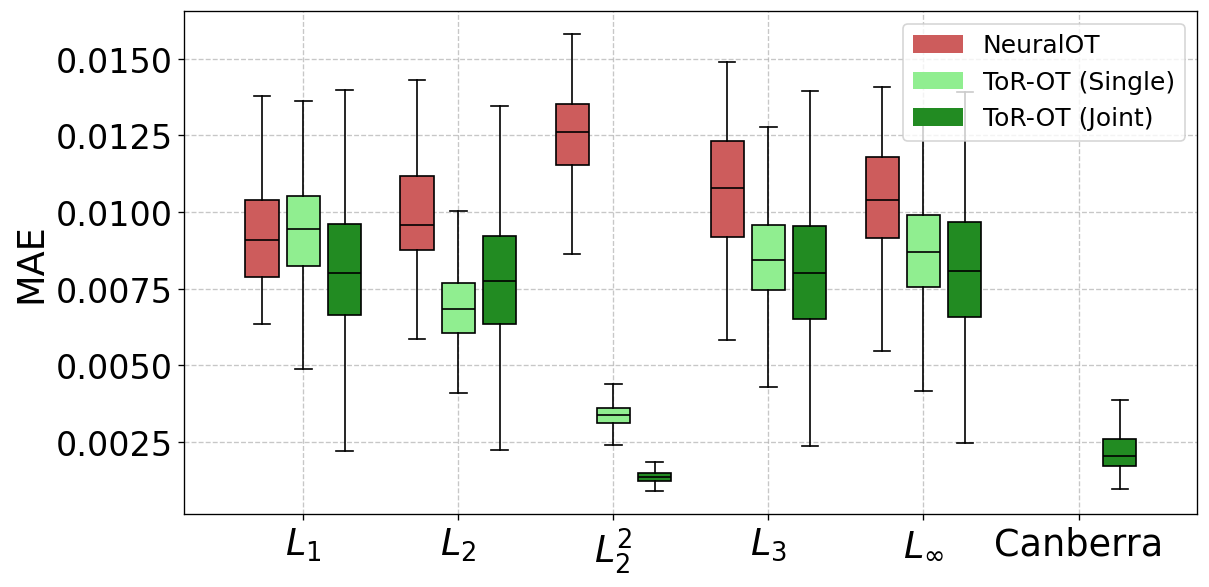

/Users/takis/anaconda3/envs/env_TF4OT/lib/python3.11/site-packages/numpy/_core/fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/Users/takis/anaconda3/envs/env_TF4OT/lib/python3.11/site-packages/numpy/_core/_methods.py:144: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


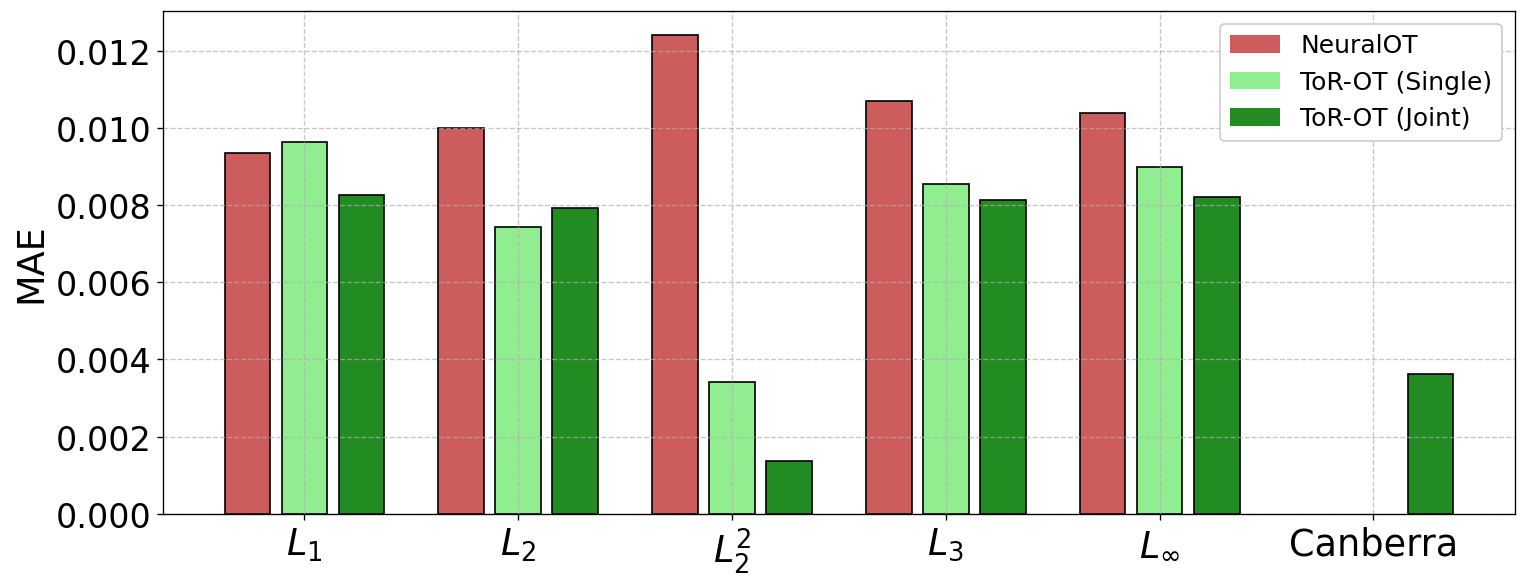

Generating Test Set Plot for MAPE...
Saved: img/1d_testset_mape.png


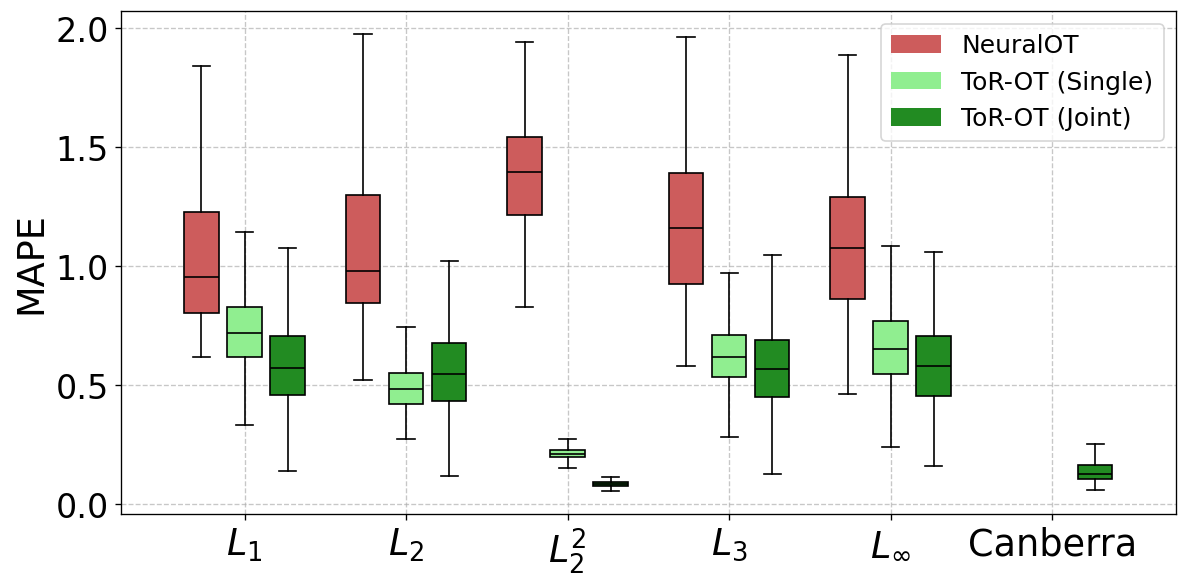

Saved: img/1d_testset_mape_bar.png


/Users/takis/anaconda3/envs/env_TF4OT/lib/python3.11/site-packages/numpy/_core/fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/Users/takis/anaconda3/envs/env_TF4OT/lib/python3.11/site-packages/numpy/_core/_methods.py:144: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


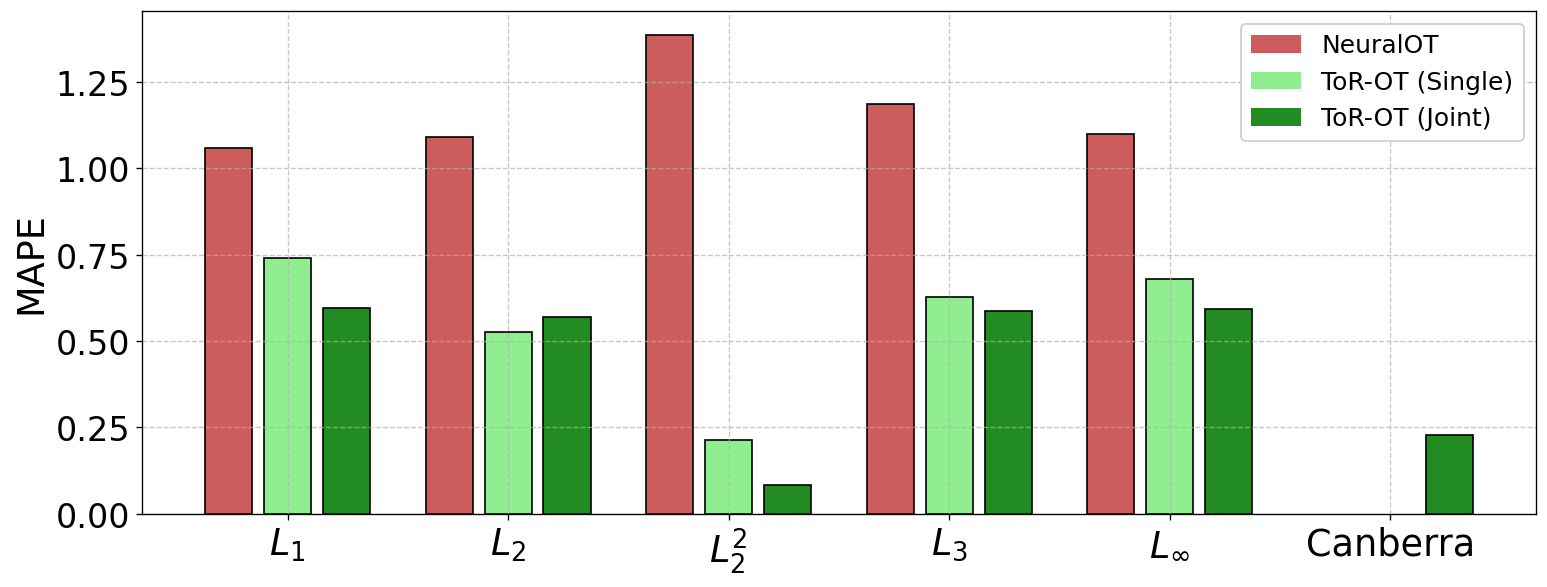

Generating Test Set Plot for Hellinger...


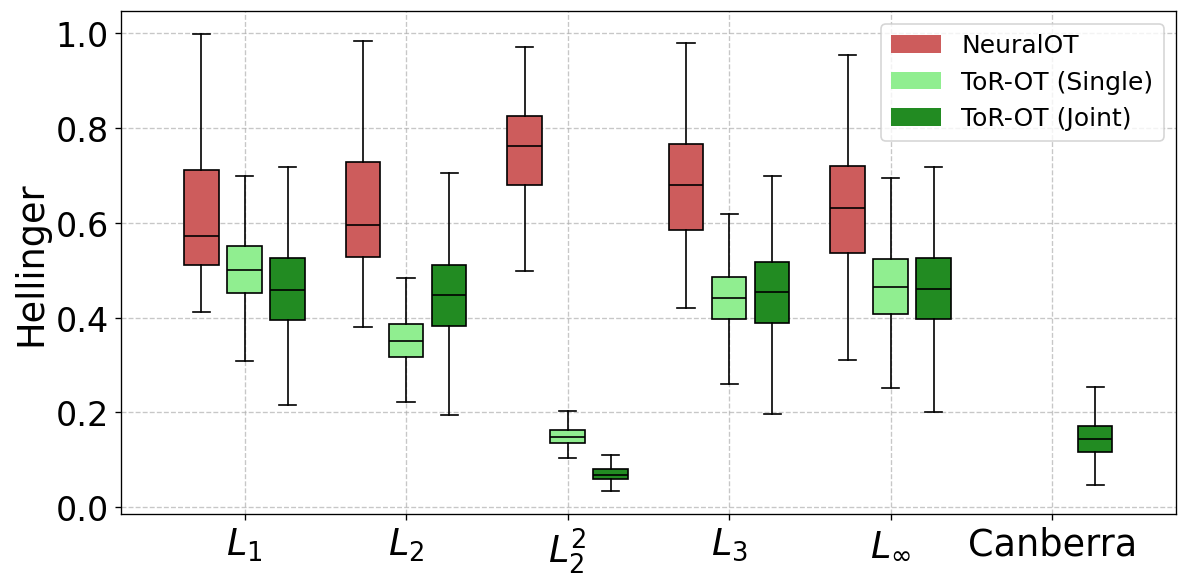

/Users/takis/anaconda3/envs/env_TF4OT/lib/python3.11/site-packages/numpy/_core/fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/Users/takis/anaconda3/envs/env_TF4OT/lib/python3.11/site-packages/numpy/_core/_methods.py:144: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


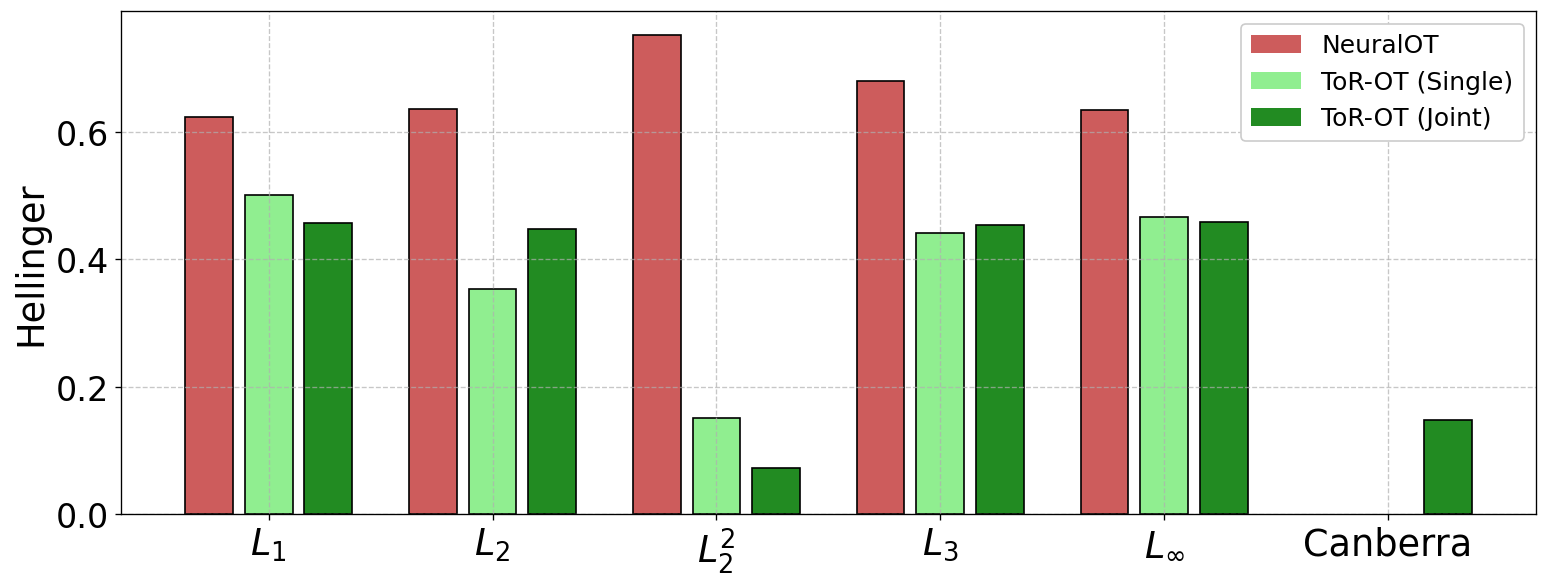

Generating Test Set Plot for OT Cost Diff...


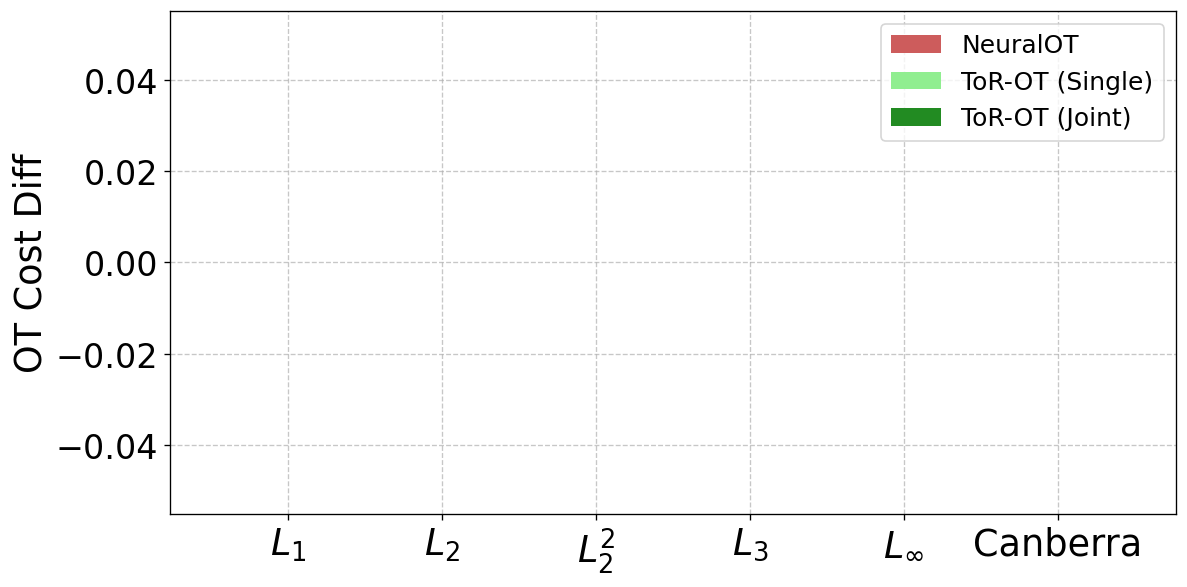

/Users/takis/anaconda3/envs/env_TF4OT/lib/python3.11/site-packages/numpy/_core/fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/Users/takis/anaconda3/envs/env_TF4OT/lib/python3.11/site-packages/numpy/_core/_methods.py:144: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


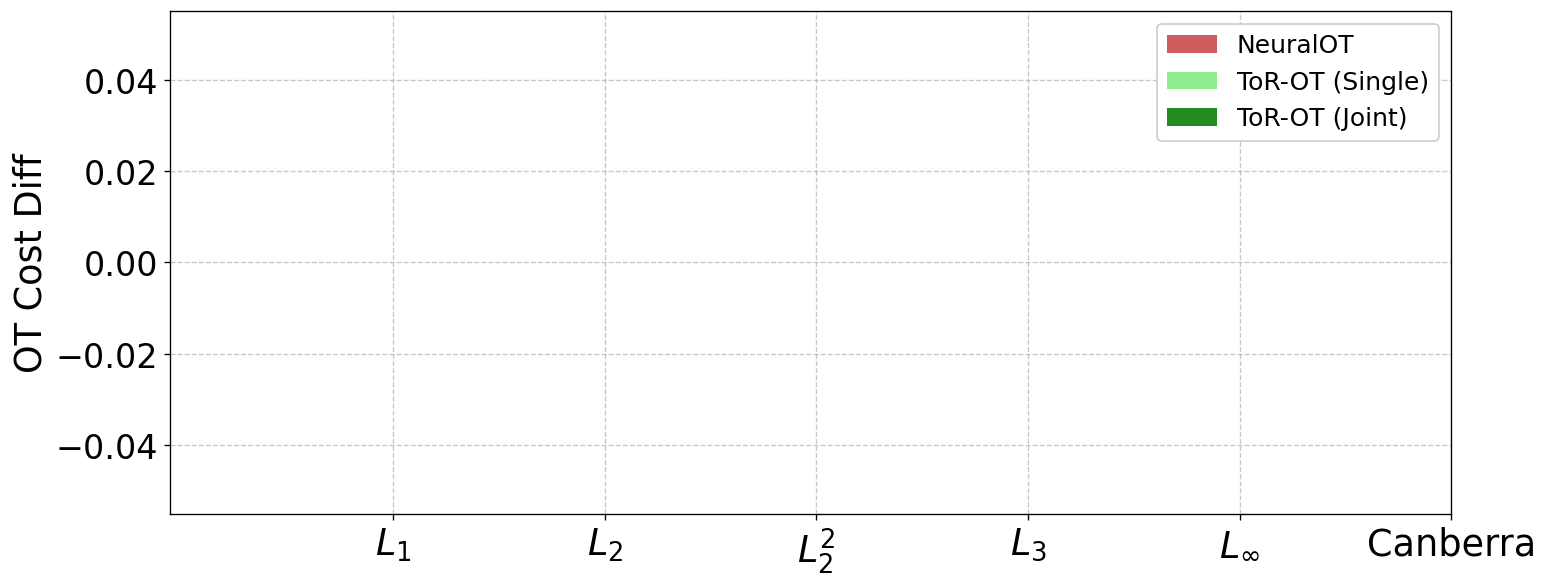

Generating Test Set Plot for Total Variation...


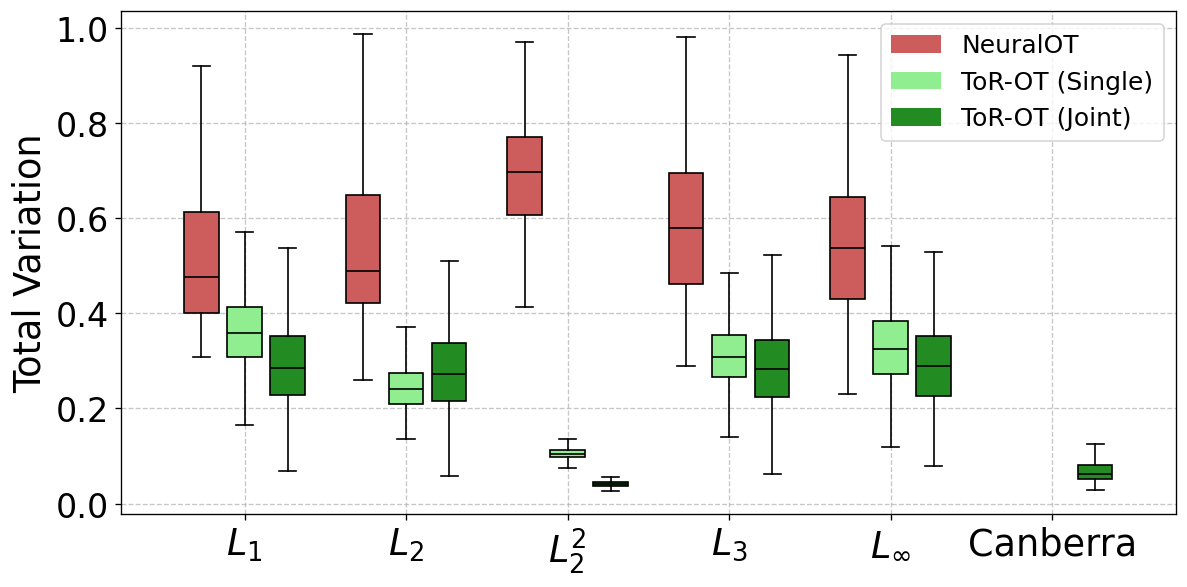

/Users/takis/anaconda3/envs/env_TF4OT/lib/python3.11/site-packages/numpy/_core/fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/Users/takis/anaconda3/envs/env_TF4OT/lib/python3.11/site-packages/numpy/_core/_methods.py:144: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


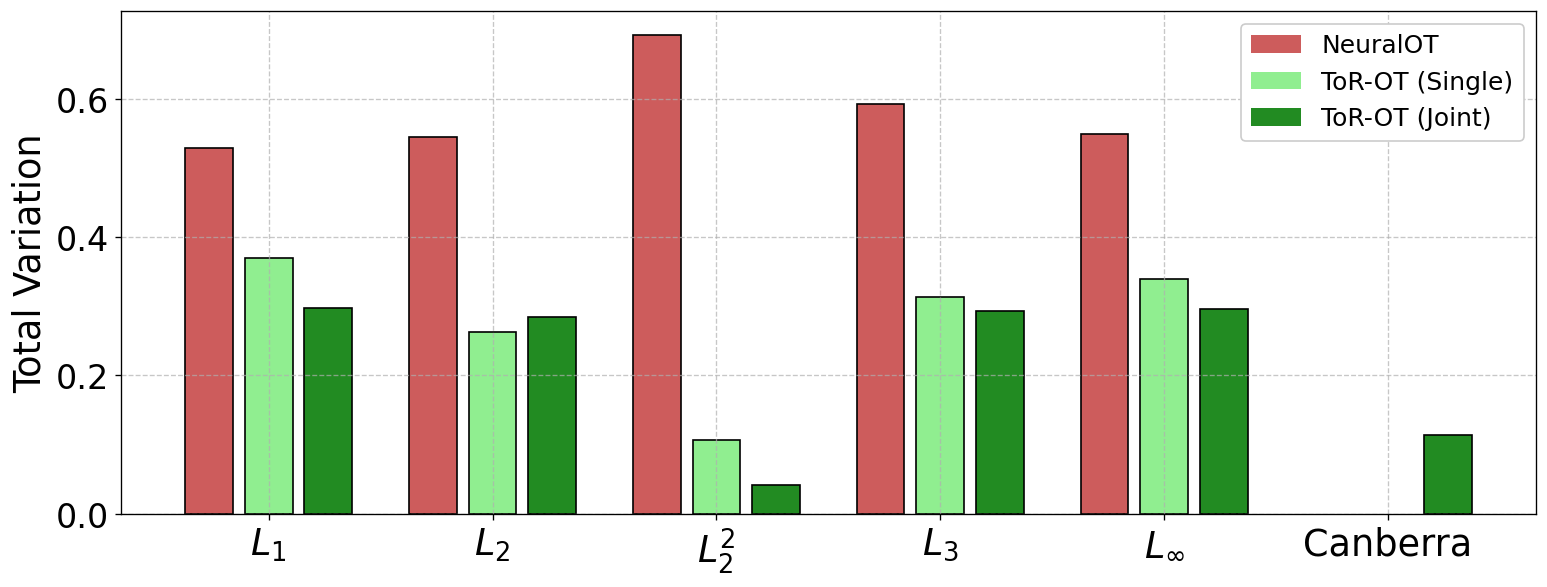

Generating Test Set Plot for Run Time (Seconds)...
Saved: img/1d_testset_run_time_seconds.png


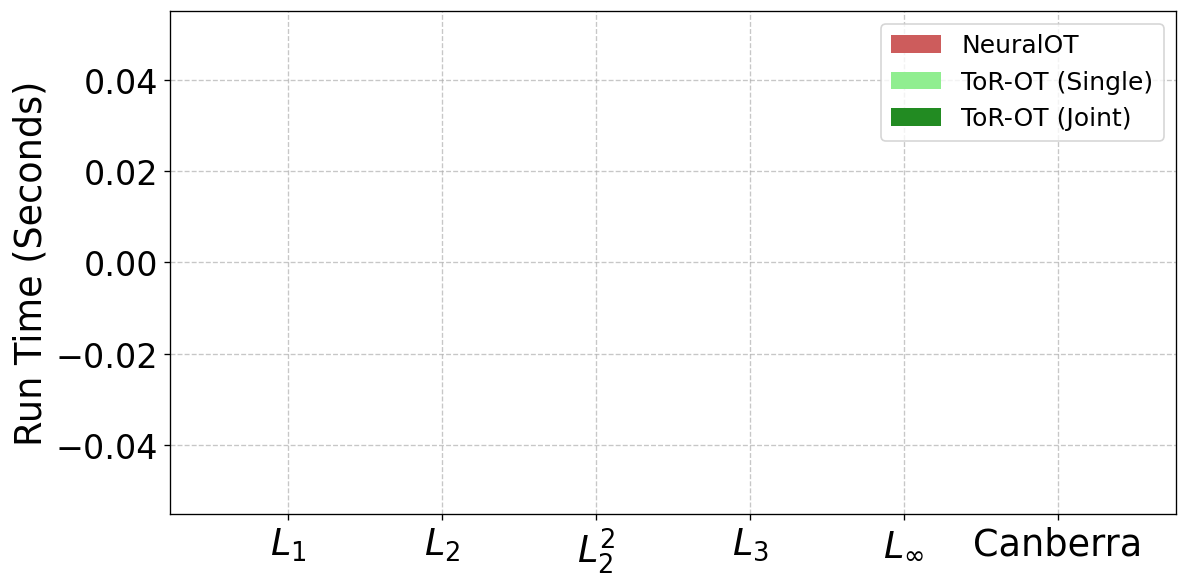

Saved: img/1d_testset_run_time_seconds_bar.png


/Users/takis/anaconda3/envs/env_TF4OT/lib/python3.11/site-packages/numpy/_core/fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/Users/takis/anaconda3/envs/env_TF4OT/lib/python3.11/site-packages/numpy/_core/_methods.py:144: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


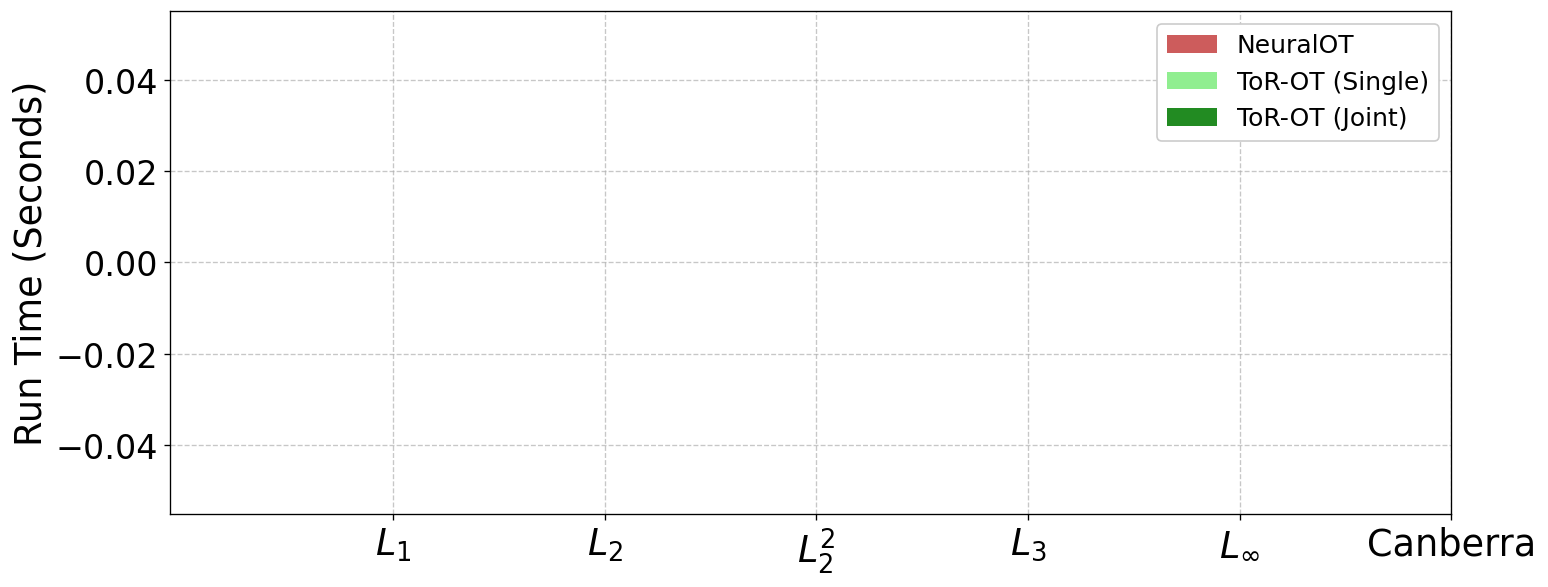

In [5]:
print("="*80)
print("TEST SET ANALYSIS")
print("="*80)

# 1. Define Helper to Load Data
def load_testset_npz(path):
    if not os.path.exists(path):
        print(f"Path does not exist: {path}")
        return None
    try:
        data = np.load(path)
        # print some of its content
        print(data.files)
        # Map npz keys to display keys. 
        # NPZ keys: 'mae', 'mape', 'hellinger', 'otcost_diff', 'tv'
        ret = {}
        if 'all_mae_sparse' in data: ret['MAE'] = data['all_mae_sparse']
        if 'all_mape_sparse' in data: ret['MAPE'] = data['all_mape_sparse']
        if 'all_hellinger_sparse' in data: ret['Hellinger'] = data['all_hellinger_sparse']
        if 'all_otcost_diff_sparse' in data: ret['OT Cost Diff'] = data['all_otcost_diff_sparse']
        if 'all_tv_sparse' in data: ret['Total Variation'] = data['all_tv_sparse']
        return ret
    except Exception as e:
        print(f"Error loading {path}: {e}")
        return None

# 2. Pre-load ALL Test Set Data
all_testset_data = {}

# Define Keys for plotting order and retrieval
# User requested keys: NOT_INDIV, TOT_INDIV, TOT_JOINT (Reordered)
TESTSET_KEYS = ['NOT_INDIV', 'TOT_INDIV', 'TOT_JOINT']

# Map keys to paths/loading logic
for metric in METRICS:
    all_testset_data[metric] = {}
    
    # INDIV Paths (Updated to include metric in filename)
    dir_indiv = os.path.join(EXPERIMENT_DIR_INDIV, MODEL_INDIV_TEMPLATE.format(metric))
    print(dir_indiv)
    
    # User requested specific paths:
    # path_indiv_tot = ... f"eval_all_testset_1d_{metric}_results_tot.npz"
    # path_indiv_not = ... f"eval_all_testset_1d_{metric}_results_not.npz"
    # Note: run_inference.py saves .npz, so we use .npz
    
    path_tot_indiv = os.path.join(dir_indiv, f"eval_all_testset_1d_{metric}_results_tot.npz")
    path_not_indiv = os.path.join(dir_indiv, f"eval_all_testset_1d_{metric}_results_not.npz")

    # JOINT Paths
    dir_joint = os.path.join(EXPERIMENT_DIR_JOINT, MODEL_JOINT_NAME)
    path_tot_joint = os.path.join(dir_joint, f"eval_all_testset_1d_{metric}_results_tot.npz")
    # path_not_joint = os.path.join(dir_joint, f"eval_all_testset_1d_results_not_{metric}.npz") # Excluded
    
    # Load and populate
    val = load_testset_npz(path_tot_indiv)
    if val: all_testset_data[metric]['TOT_INDIV'] = val
        
    val = load_testset_npz(path_not_indiv)
    if val: all_testset_data[metric]['NOT_INDIV'] = val
        
    val = load_testset_npz(path_tot_joint)
    if val: all_testset_data[metric]['TOT_JOINT'] = val

# display some results for testing, format the dict to be more readable
print("All Test Set Data:")
for metric, data in all_testset_data.items():
    print(f"Metric: {metric}")
    for key, values in data.items():
        print(f"  {key}: {values}")


# 3. Generate Plots (One per Performance Metric)
# Colors matching the keys: IndianRed (NOT), Lavender (TOT), LightGreen (TOT_JOINT)
# Reordered matches TESTSET_KEYS: ['NOT_INDIV', 'TOT_INDIV', 'TOT_JOINT']
TESTSET_COLORS = ['indianred', 'lightgreen', 'forestgreen']
mpl.rcParams['ytick.labelsize'] = 20

for perf_metric in PERFORMANCE_METRICS:
    print(f"Generating Test Set Plot for {perf_metric}...")
    
    plot_data = []
    valid_dist_metrics = [] # Distance metrics that have data
    
    # Collect data across all distance metrics
    for dist_metric in METRICS:
        if dist_metric not in all_testset_data:
            continue
            
        # Check if we have ANY data for this distance metric
        if not all_testset_data[dist_metric]:
            continue
            
        # We found some data, so this X-axis point is valid
        valid_dist_metrics.append(dist_metric)
        
        # Append data for each Model Key in order
        for key in TESTSET_KEYS:
            model_data = all_testset_data[dist_metric].get(key, {})
            # extract_metrics was used before, but here we load npz directly which returns dict of arrays
            values = model_data.get(perf_metric, [])
            
            # Clean NaNs
            if isinstance(values, np.ndarray):
                values = values[~np.isnan(values)] if len(values) > 0 else []
            elif isinstance(values, list):
                 values = [v for v in values if v is not None]
                 
            plot_data.append(values)

    if not plot_data:
        print(f"No data found for {perf_metric}")
        continue

    # Setup Plot
    fig, ax = plt.subplots(figsize=(10, 5), dpi=120)

    # Position calculations
    num_distance_metrics = len(valid_dist_metrics)
    num_bars_per_group = len(TESTSET_KEYS)
    group_width = 0.8
    bar_width = group_width / num_bars_per_group

    positions = []
    for i in range(num_distance_metrics):
        center = i + 1
        start_offset = -(num_bars_per_group - 1) * bar_width / 2.0
        for j in range(num_bars_per_group):
            offset = start_offset + (j * bar_width)
            positions.append(center + offset)

    # Boxplot
    bp = ax.boxplot(plot_data, positions=positions, widths=bar_width*0.8, 
                    patch_artist=True, medianprops=dict(color="black"), showfliers=False)

    # Color values
    for i, patch in enumerate(bp['boxes']):
        color_idx = i % num_bars_per_group
        patch.set_facecolor(TESTSET_COLORS[color_idx])

    # X-axis Labels
    ax.set_xticks(range(1, num_distance_metrics + 1))
    xtick_labels = [METRIC_LABELS.get(m, m) for m in valid_dist_metrics]
    ax.set_xticklabels(xtick_labels, rotation=0, ha='center', fontsize=22)

    # Title and Grid
    #ax.set_title(f'Test Set comparison: {perf_metric} across cost types', fontsize=24)
    ax.set_ylabel(perf_metric, fontsize=22)
    ax.grid(True, linestyle='--', alpha=0.7)

    # Legend
    from matplotlib.patches import Patch
    legend_elements = [
        Patch(facecolor=TESTSET_COLORS[i], label=LABEL_MAPPING.get(TESTSET_KEYS[i], TESTSET_KEYS[i]))
        for i in range(len(TESTSET_KEYS))
    ]
    ax.legend(handles=legend_elements, loc='upper right', fontsize=15)

    plt.tight_layout()
    # Save only selected metrics
    if perf_metric in ['MAPE', 'Run Time (Seconds)']:
        # make a filesystem-safe name like: testset_mape.png, testset_run_time_seconds.png
        safe_metric = re.sub(r'[^a-z0-9]+', '_', perf_metric.lower()).strip('_')
        out_png = f"img/1d_testset_{safe_metric}.png"
        plt.savefig(out_png, bbox_inches='tight', dpi=300)
        print(f"Saved: {out_png}")
    plt.show()




    fig, ax = plt.subplots(figsize=(13, 5), dpi=120)

    plot_data_np = np.array([np.mean(plot_data[i]) for i in range(len(plot_data))])
    bp = ax.bar(positions, plot_data_np, width=bar_width*0.8, facecolor=5*COLORS, edgecolor='black')

    # X-axis Labels
    ax.set_xticks(range(1, num_distance_metrics + 1))
    xtick_labels = [METRIC_LABELS.get(m, m) for m in valid_dist_metrics]
    ax.set_xticklabels(xtick_labels, rotation=0, ha='center', fontsize=22)

    # Title and Grid
    #ax.set_title(f'Test Set comparison: {perf_metric} across cost types', fontsize=24)
    ax.set_ylabel(perf_metric, fontsize=22)
    ax.grid(True, linestyle='--', alpha=0.7)

    # Legend
    from matplotlib.patches import Patch
    legend_elements = [
        Patch(facecolor=TESTSET_COLORS[i], label=LABEL_MAPPING.get(TESTSET_KEYS[i], TESTSET_KEYS[i]))
        for i in range(len(TESTSET_KEYS))
    ]
    ax.legend(handles=legend_elements, loc='upper right', fontsize=15, framealpha=1)
    
    plt.tight_layout()
    # Save only selected metrics
    if perf_metric in ['MAPE', 'Run Time (Seconds)']:
        # make a filesystem-safe name like: testset_mape.png, testset_run_time_seconds.png
        safe_metric = re.sub(r'[^a-z0-9]+', '_', perf_metric.lower()).strip('_')
        out_png = f"img/1d_testset_{safe_metric}_bar.png"
        plt.savefig(out_png, bbox_inches='tight', dpi=300)
        print(f"Saved: {out_png}")
    plt.show()

# Joint Model vs Neural OT Comparison (Heatmap)

This section compares the 'sqeuclidean' OT Cost Difference between the Joint Model (TOT) and Neural OT (NOT). The heatmap shows the percentage of improvement of the Joint Model over Neural OT.


Generating Heatmap for cityblock
Loading TOT data...
Loading NOT data...
Matrix Dimensions: 9x9


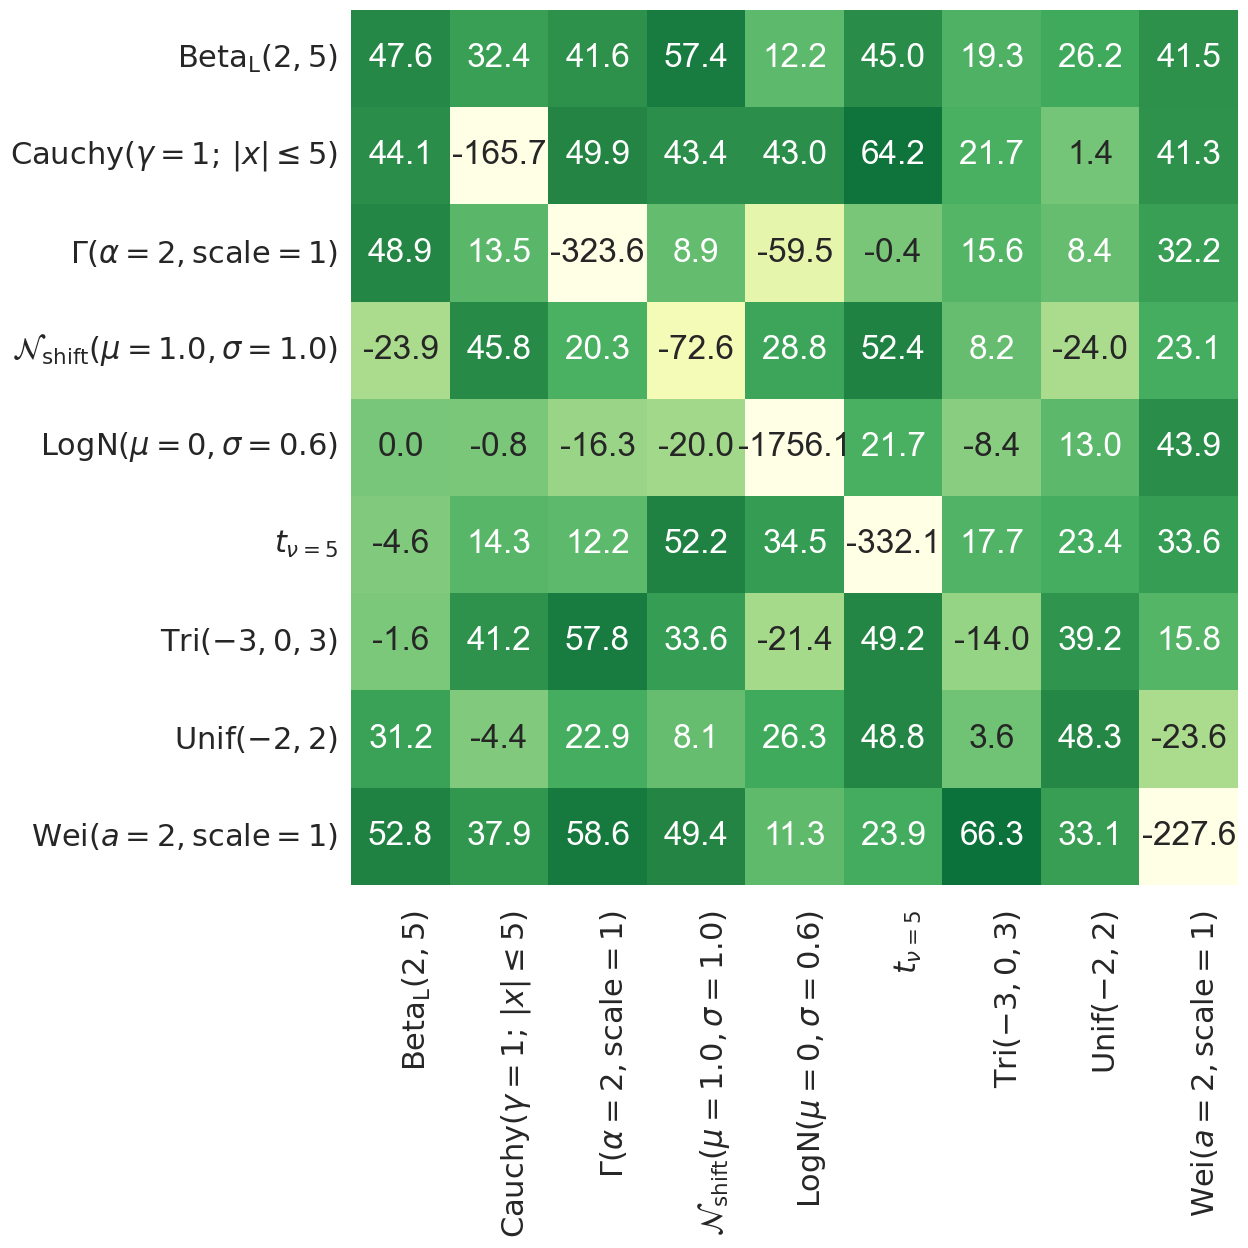


Generating Heatmap for euclidean
Loading TOT data...
Loading NOT data...
Matrix Dimensions: 9x9


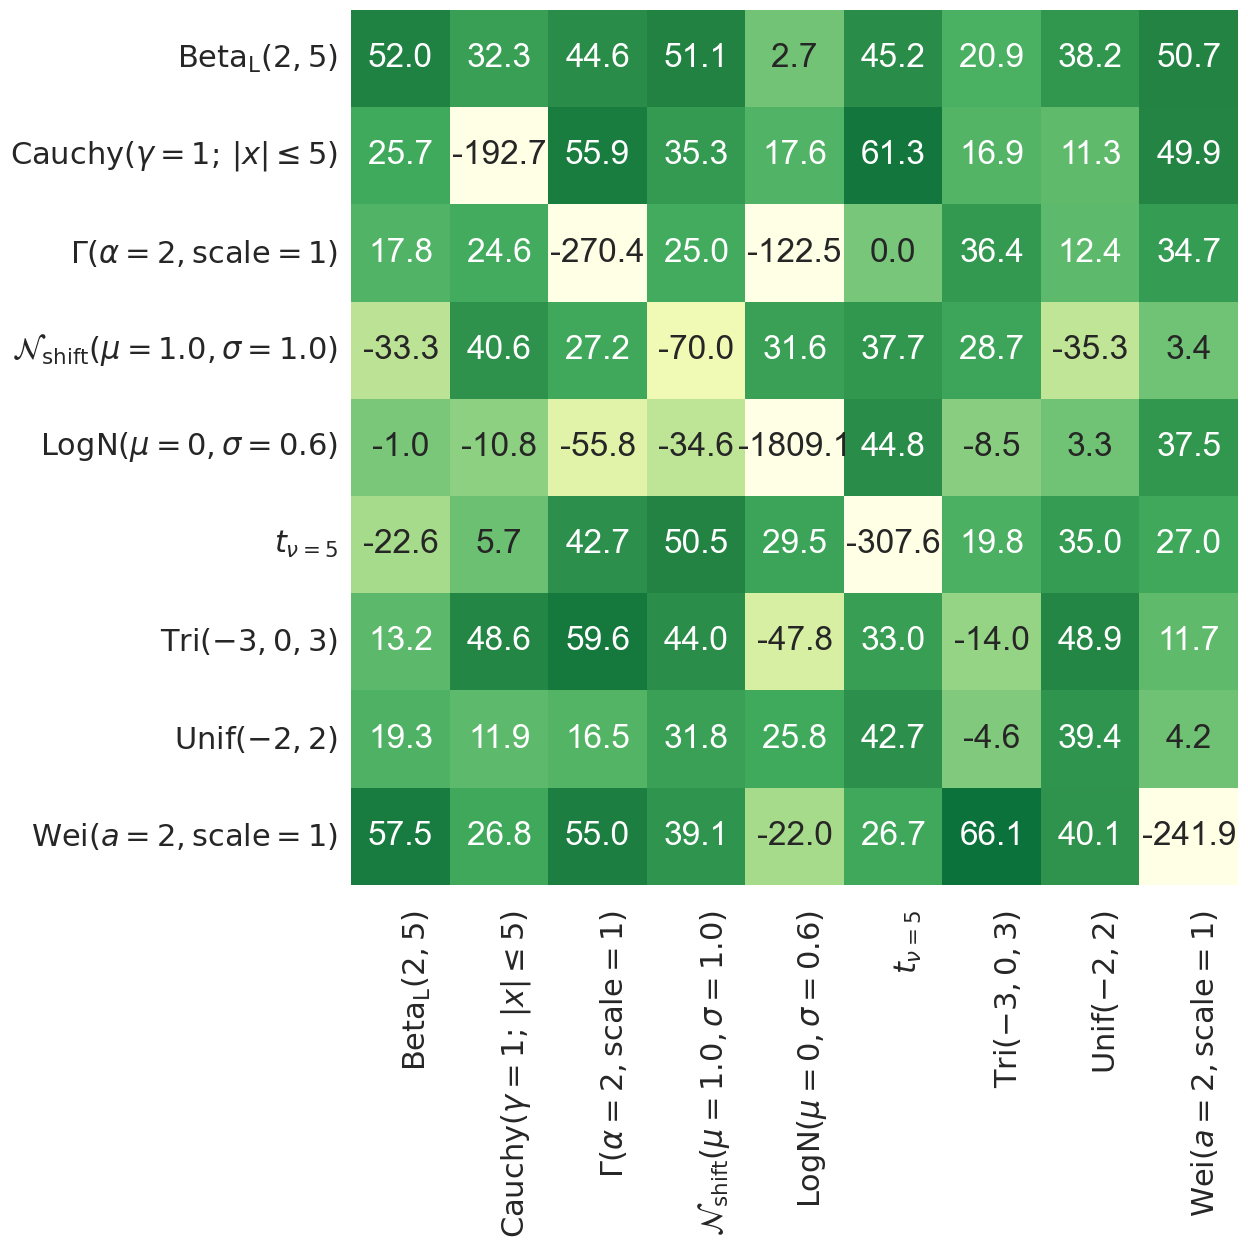


Generating Heatmap for sqeuclidean
Loading TOT data...
Loading NOT data...
Matrix Dimensions: 9x9
Saved: img/1d_heatmap_improvement_sqeuclidean.png


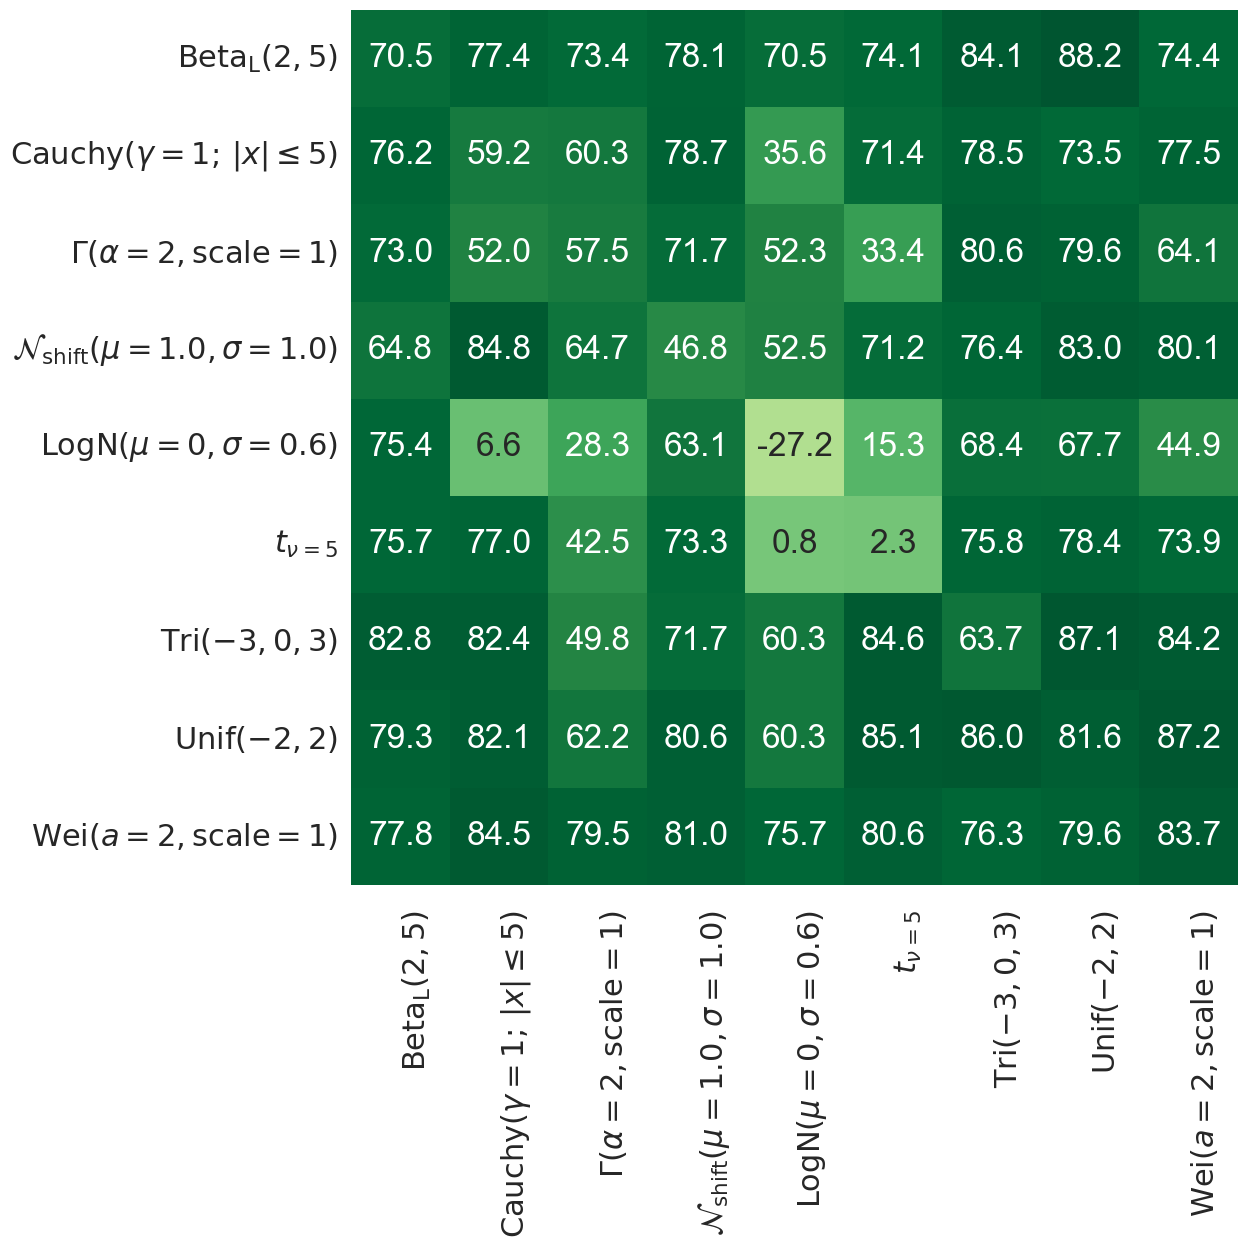


Generating Heatmap for minkowski
Loading TOT data...
Loading NOT data...
Matrix Dimensions: 9x9


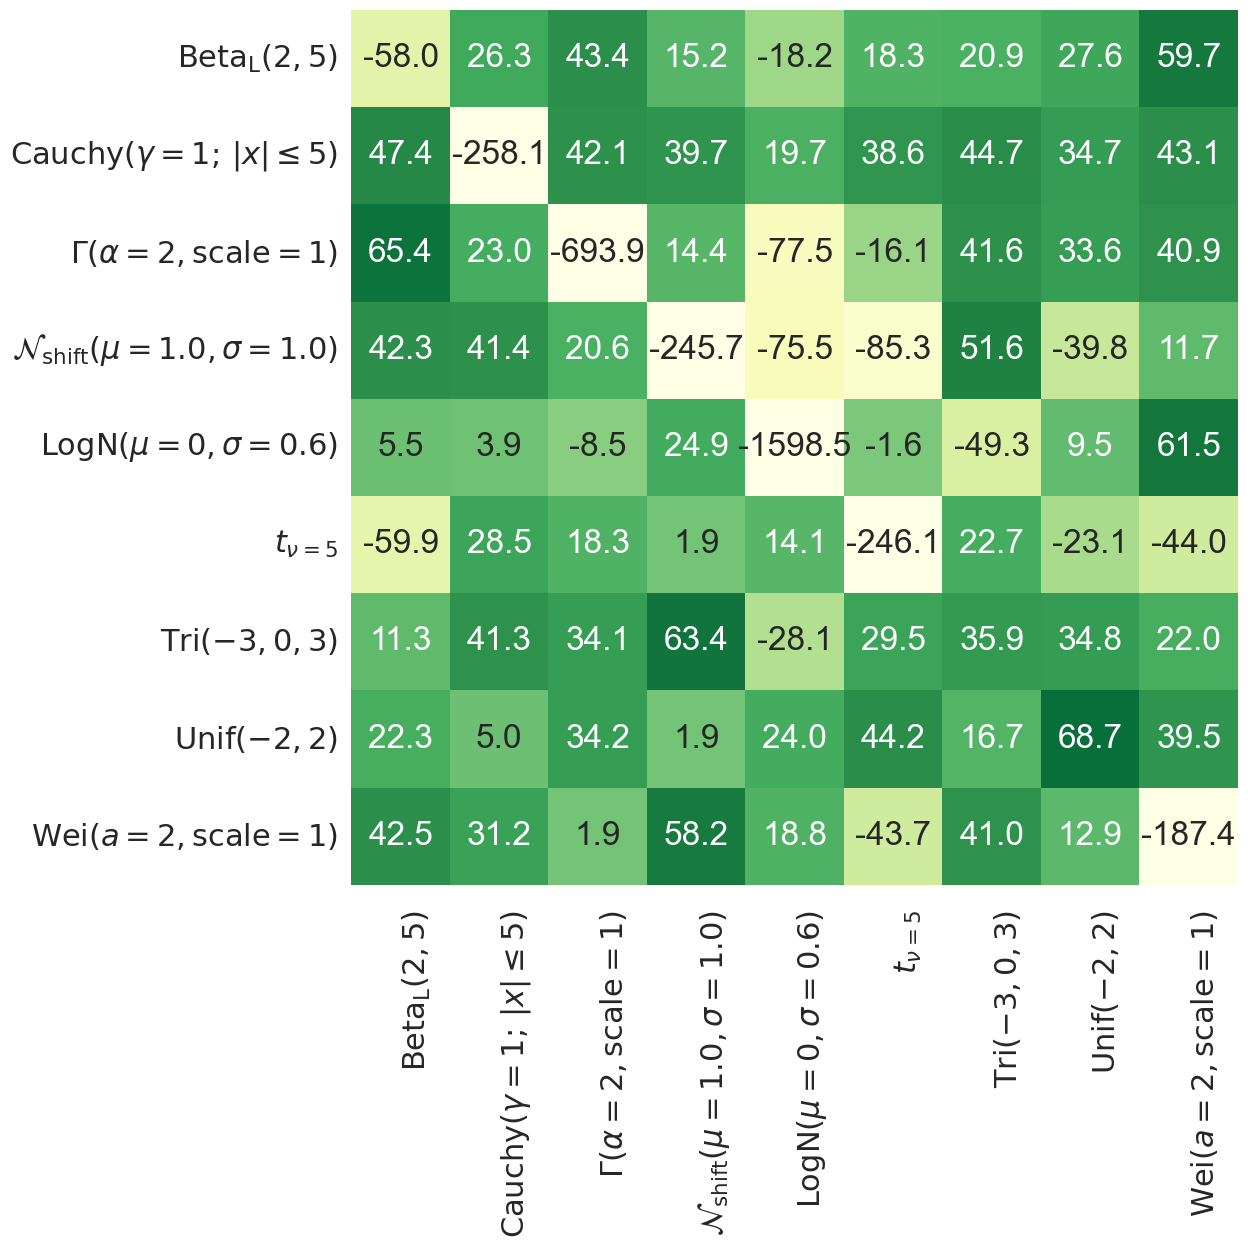


Generating Heatmap for chebyshev
Loading TOT data...
Loading NOT data...
Matrix Dimensions: 9x9


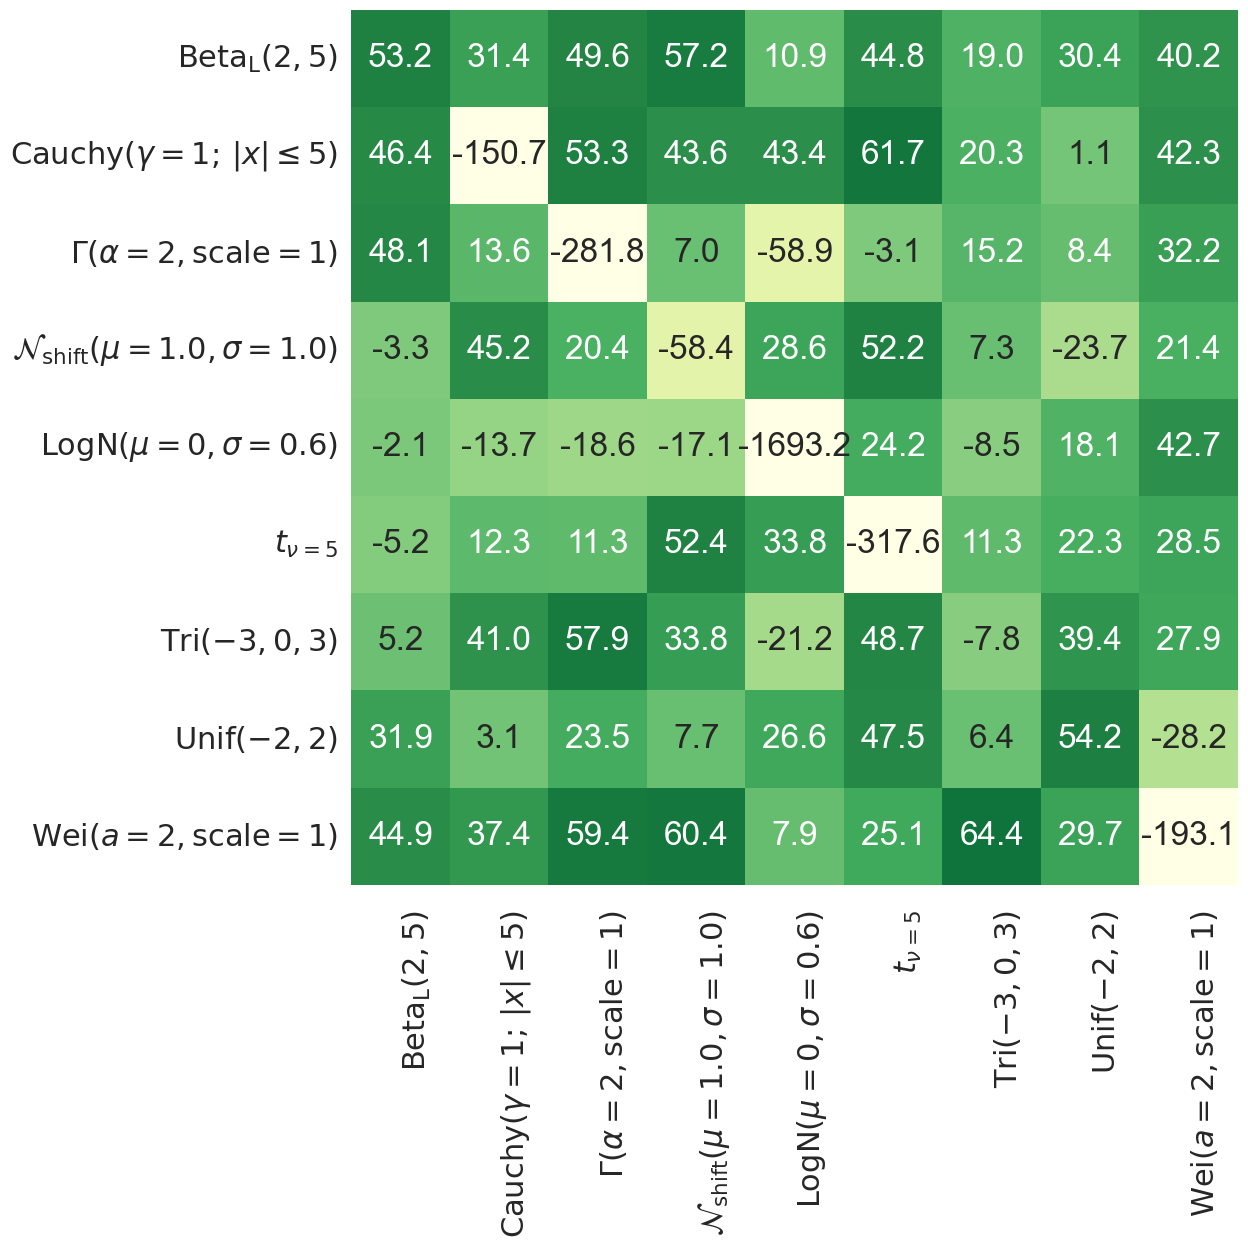


Generating Heatmap for canberra
Skipping canberra, detailed results file not found:
  TOT: ../../../experiments/cost_semivariable/model_dim768_context512_tflayers24_tfheads16_num_prefix1_dropout0_flashTrue_data600K_rowwise_costsemivariable_prec4_bins30_DigitTokenizer_epochs25_batch128/eval_all_pairs_1d_canberra_results_tot.npy
  NOT: ../../../experiments/cost_fixed/model_dim768_context512_tflayers24_tfheads16_num_prefix1_dropout0_flashTrue_data100K_rowwise_costfixed_prec4_bins30_DigitTokenizer_epochs50_batch192_canberra/eval_all_pairs_1d_canberra_results_not.npy


In [11]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Loop over metrics to generate heatmaps
for metric in METRICS:
    print(f"\n{'='*40}\nGenerating Heatmap for {metric}\n{'='*40}")
    
    # Define Dynamic Paths for 'eval_all_pairs' (Detailed results for heatmap)
    # TOT (Joint Model)
    dir_joint = os.path.join(EXPERIMENT_DIR_JOINT, MODEL_JOINT_NAME)
    path_tot = os.path.join(dir_joint, f"eval_all_pairs_1d_{metric}_results_tot.npy")
    
    # NOT (Individual Model - baseline)
    dir_indiv = os.path.join(EXPERIMENT_DIR_INDIV, MODEL_INDIV_TEMPLATE.format(metric))
    path_not = os.path.join(dir_indiv, f"eval_all_pairs_1d_{metric}_results_not.npy")

    if not os.path.exists(path_tot) or not os.path.exists(path_not):
        print(f"Skipping {metric}, detailed results file not found:\n  TOT: {path_tot}\n  NOT: {path_not}")
        continue

    # Load Data
    print(f"Loading TOT data...")
    data_tot = np.load(path_tot, allow_pickle=True)
    print(f"Loading NOT data...")
    data_not = np.load(path_not, allow_pickle=True)
    
    # -----------------------------
    # LaTeX labels
    # -----------------------------
    DIST_TEX = {
        "BetaLeft":        r'$\mathrm{Beta_L}(2,5)$',
        "BetaRight":       r'$\mathrm{Beta_R}(5,2)$',
        "Laplace":         r'$\mathrm{Lap}(0,1)$',
        "Uniform":         r'$\mathrm{Unif}(-2,2)$',
        "StudentT":        r'$t_{\nu=5}$',
        "GaussianShifted": r'$\mathcal{N}_{\mathrm{shift}}(\mu=1.0,\sigma=1.0)$',
        "LogNormal":       r'$\mathrm{LogN}(\mu=0,\sigma=0.6)$',
        "CauchyTrunc":     r'$\mathrm{Cauchy}(\gamma=1;\,|x|\leq 5)$',
        "Triangular":      r'$\mathrm{Tri}(-3,0,3)$',
        "Exponential":     r'$\mathrm{Exp}(\mathrm{scale}=1)$',
        "Weibull":         r'$\mathrm{Wei}(a=2,\mathrm{scale}=1)$',
        "Gamma":           r'$\Gamma(\alpha=2,\mathrm{scale}=1)$',
    }

    def tex(name: str) -> str:
        safe = str(name).replace('_', r'\_')
        return DIST_TEX.get(name, rf'$\mathrm{{{safe}}}$')

    # Extract Unique Distributions
    sources = sorted(list(set([item['source'] for item in data_tot])))
    targets = sorted(list(set([item['target'] for item in data_tot])))
    
    # --------------------------------
    # Exclude specific distributions
    # --------------------------------
    EXCLUDE_DISTS = {"Exponential", "Laplace", "BetaRight", }
    sources = [s for s in sources if s not in EXCLUDE_DISTS]
    targets = [t for t in targets if t not in EXCLUDE_DISTS]
    # --------------------------------
    n_sources = len(sources)
    n_targets = len(targets)
    
    print(f"Matrix Dimensions: {n_sources}x{n_targets}")
    
    # Initialize Matrix
    improvement_matrix = np.zeros((n_sources, n_targets))
    
    # Helper to find item
    def find_item(data, s, t):
        for item in data:
            if item['source'] == s and item['target'] == t:
                return item
        return None
    
    eps = 1e-12
    valid_entries = 0
    
    for i, s in enumerate(sources):
        for j, t in enumerate(targets):
            item_tot = find_item(data_tot, s, t)
            item_not = find_item(data_not, s, t)
            
            if item_tot is not None and item_not is not None:
                # Use: 'otcost_diff', 'mae_sparse', 'mape_sparse', 'hellinger_sparse', 'tv_sparse'
                val_tot = item_tot.get('mape_sparse', np.nan)
                val_not = item_not.get('mape_sparse', np.nan)
                
                if not np.isnan(val_tot) and not np.isnan(val_not):
                   # % reduction in error
                   improvement_pct = 100.0 * (val_not - val_tot) / max(val_not, eps)
                   improvement_matrix[i, j] = improvement_pct
                   valid_entries += 1
                else:
                   improvement_matrix[i, j] = np.nan
            else:
                improvement_matrix[i, j] = np.nan

    if valid_entries == 0:
        print("No valid data points found for intersection of sources/targets.")
        continue

    # Plot
    plt.style.use("default")
    plt.figure(figsize=(13, 13))
    sns.set(font_scale=2)
    
    xlabels = [tex(t) for t in targets]
    ylabels = [tex(s) for s in sources]
    
    ax = sns.heatmap(
        improvement_matrix,
        annot=True, fmt=".1f",
        xticklabels=xlabels,
        yticklabels=ylabels,
        cmap="YlGn",
        center=0,
        cbar=False,
        vmax=100,
        vmin=-100,
    )
    
    #plt.title(rf'$\%%$ Improvement of ToR-OT (Joint) over Neural OT ({metric})', fontsize=24)
    # plt.xlabel("Target Distribution", fontsize=22)
    # plt.ylabel("Source Distribution", fontsize=22)
    plt.xticks(rotation=90, ha='center')
    plt.yticks(rotation=0)
        # ---- Improve rotated xtick label spacing ----
    ax.tick_params(axis="x", which="major", pad=12)          # push labels away from axis
    plt.setp(ax.get_xticklabels(), rotation=90, ha="right", rotation_mode="anchor")
    plt.subplots_adjust(bottom=0.22)                         # extra room for rotated labels
    plt.tight_layout()
    if metric == "sqeuclidean":
        safe_metric = re.sub(r'[^a-z0-9]+', '_', metric.lower()).strip('_')
        out_png = f"img/1d_heatmap_improvement_{safe_metric}.png"
        os.makedirs(os.path.dirname(out_png), exist_ok=True)
        plt.savefig(out_png, bbox_inches="tight", dpi=300)
        print(f"Saved: {out_png}")
    plt.show()
